In [1]:
# -*- coding: utf-8 -*-
"""
Генератор лабораторной №6 «Корреляционный анализ при выявлении
признаков дробления бизнеса» — 10 отраслевых вариантов.
Создаёт:
  ЛР6_Варианты.xlsx  — данные (лист на вариант, без справочника)
  ЛР6_Ответы.docx    — ожидаемые результаты + сводная таблица по вариантам
"""

import numpy as np
import pandas as pd
from datetime import date
from dateutil.relativedelta import relativedelta
from openpyxl import Workbook
from docx import Document
from docx.shared import Pt

RNG = np.random.default_rng(42)
LIMIT_USN = 450.0
START = date(2023, 1, 1)
MONTHS = 36

# ---------------------------------------------------------------------------
# 1. Справочники вариантов
# ---------------------------------------------------------------------------
VARIANTS = {}

def _pack(industry, rows):
    return {"industry": industry, "rows": rows}

VARIANTS["1. Ритейл"] = _pack("Ритейл", [
    ("Р1","ООО «ПродМаркет»","ОСНО","base",438,97,1.5,18,0.78,"у лимита"),
    ("Р2","ООО «ПродМаркет-Регион»","УСН","tech_pair",120,27,34,22,0.71,"пара с Р1"),
    ("Р3","ООО «Свежий Путь»","УСН","tech_zero",85,19,28,2.1,0.14,"σ<3%"),
    ("Р4","ООО «Гастроном 24»","УСН","tech_zero",60,13,31,1.8,0.11,"σ<3%"),
    ("Р5","ООО «Лавка Плюс»","УСН","tech_zero",95,21,26,2.6,0.17,"σ<3%"),
    ("Р6","ООО «ПродМаркет-Юг»","УСН","near_limit",425,94,2.0,16,0.69,"у лимита"),
    ("Р7","ООО «ПродМаркет-Восток»","УСН","near_limit",418,93,1.2,19,0.72,"у лимита"),
    ("Р8","ООО «Пятёрочка у дома»","УСН","normal",210,47,15,22,0.75,"—"),
    ("Р9","ООО «Магнолия»","УСН","normal",180,40,12,20,0.72,"—"),
    ("Р10","ООО «Корзинка»","УСН","normal",150,33,10,18,0.70,"—"),
    ("Р11","ООО «Фреш Лайн»","УСН","normal",130,29,9,17,0.68,"—"),
    ("Р12","ООО «Продукты 24/7»","УСН","normal",110,24,8,16,0.66,"—"),
    ("Р13","ООО «Вкусный Дом»","УСН","normal",100,22,11,19,0.71,"—"),
    ("Р14","ООО «Молочная Лавка»","УСН","normal",90,20,10,18,0.69,"—"),
    ("Р15","ООО «Хлеб & Соль»","УСН","normal",95,21,9,17,0.67,"—"),
])

VARIANTS["2. Девелоперы"] = _pack("Девелоперы", [
    ("Д1","ООО «СтройИнвестГрупп»","ОСНО","base",445,99,0.8,20,0.81,"у лимита"),
    ("Д2","ООО «СтройИнвестГрупп-Девелопмент»","УСН","tech_pair",150,33,41,24,0.74,"пара с Д1"),
    ("Д3","ООО «ГрадСтрой»","УСН","tech_zero",70,16,38,2.4,0.15,"σ<3%"),
    ("Д4","ООО «Новосёл»","УСН","tech_zero",55,12,35,2.0,0.12,"σ<3%"),
    ("Д5","ООО «СтройИнвест-Юг»","УСН","near_limit",430,96,1.7,17,0.70,"у лимита"),
    ("Д6","ООО «СтройИнвест-Запад»","УСН","near_limit",420,93,2.2,18,0.73,"у лимита"),
    ("Д7","ООО «ЖилКапитал»","ОСНО","normal",300,67,18,26,0.80,"—"),
    ("Д8","ООО «Панорама»","УСН","normal",250,56,15,24,0.78,"—"),
    ("Д9","ООО «Квартал 77»","УСН","normal",220,49,13,22,0.76,"—"),
    ("Д10","ООО «Высота»","УСН","normal",190,42,12,21,0.74,"—"),
    ("Д11","ООО «СтройГарант»","ОСНО","normal",170,38,11,20,0.72,"—"),
    ("Д12","ООО «Мегаполис-Строй»","УСН","normal",150,33,10,19,0.70,"—"),
    ("Д13","ООО «Бетон-Сервис»","УСН","normal",120,27,9,18,0.68,"—"),
    ("Д14","ООО «Фасад-Про»","УСН","normal",100,22,8,17,0.66,"—"),
    ("Д15","ООО «Уютный Дом»","УСН","normal",90,20,7,16,0.65,"—"),
])

VARIANTS["3. Логистика"] = _pack("Логистика", [
    ("Л1","ООО «ТрансЛогистик»","ОСНО","base",442,98,1.1,21,0.80,"у лимита"),
    ("Л2","ООО «ТрансЛогистик-Экспресс»","УСН","tech_pair",130,29,36,23,0.72,"пара с Л1"),
    ("Л3","ООО «АвтоПеревозки»","УСН","tech_zero",75,17,33,2.3,0.13,"σ<3%"),
    ("Л4","ООО «ГрузТранс»","УСН","tech_zero",65,14,30,1.9,0.10,"σ<3%"),
    ("Л5","ООО «Логистик-Про»","УСН","tech_zero",90,20,29,2.7,0.16,"σ<3%"),
    ("Л6","ООО «ТрансЛогистик-Север»","УСН","near_limit",428,95,1.9,15,0.68,"у лимита"),
    ("Л7","ООО «Магистраль»","ОСНО","normal",260,58,20,25,0.79,"—"),
    ("Л8","ООО «Дальнобой»","УСН","normal",230,51,18,24,0.77,"—"),
    ("Л9","ООО «ТрансСервис»","УСН","normal",200,44,16,23,0.75,"—"),
    ("Л10","ООО «Скорость»","УСН","normal",180,40,14,22,0.73,"—"),
    ("Л11","ООО «Карго-Лайн»","УСН","normal",160,36,12,21,0.71,"—"),
    ("Л12","ООО «АвтоЛогист»","УСН","normal",140,31,11,20,0.69,"—"),
    ("Л13","ООО «РефТранс»","УСН","normal",120,27,10,19,0.67,"—"),
    ("Л14","ООО «Путь-Дорога»","УСН","normal",100,22,9,18,0.65,"—"),
    ("Л15","ООО «ЕвроТранс»","УСН","normal",90,20,8,17,0.64,"—"),
])

VARIANTS["4. IT"] = _pack("IT", [
    ("И1","ООО «ТехноСофт»","ОСНО","base",447,99,0.6,22,0.82,"у лимита"),
    ("И2","ООО «ТехноСофт-Лаб»","УСН","tech_pair",160,36,44,25,0.75,"пара с И1"),
    ("И3","ООО «КодВоркс»","УСН","tech_zero",80,18,40,2.2,0.12,"σ<3%"),
    ("И4","ООО «Диджитал-Солюшнс»","УСН","tech_zero",50,11,37,1.7,0.09,"σ<3%"),
    ("И5","ООО «ТехноСофт-Облако»","УСН","near_limit",432,96,1.4,16,0.71,"у лимита"),
    ("И6","ООО «ТехноСофт-Интеграция»","УСН","near_limit",422,94,2.1,19,0.74,"у лимита"),
    ("И7","ООО «СофтЛайн»","ОСНО","normal",280,62,22,26,0.81,"—"),
    ("И8","ООО «АйТи-Прогресс»","УСН","normal",240,53,19,25,0.79,"—"),
    ("И9","ООО «Веб-Студия Плюс»","УСН","normal",200,44,17,24,0.77,"—"),
    ("И10","ООО «Дата-Центр»","УСН","normal",180,40,15,23,0.75,"—"),
    ("И11","ООО «НейроЛаб»","УСН","normal",150,33,13,22,0.73,"—"),
    ("И12","ООО «КиберСофт»","УСН","normal",130,29,12,21,0.71,"—"),
    ("И13","ООО «Мобайл-Дев»","УСН","normal",110,24,10,20,0.69,"—"),
    ("И14","ООО «Клауд-Сервис»","УСН","normal",90,20,9,19,0.67,"—"),
    ("И15","ООО «Пиксель-Про»","УСН","normal",80,18,8,18,0.65,"—"),
])

VARIANTS["5. Металлургия"] = _pack("Металлургия", [
    ("М1","ООО «МеталлТрейд»","ОСНО","base",440,98,1.3,19,0.79,"у лимита"),
    ("М2","ООО «МеталлТрейд-Регион»","УСН","tech_pair",140,31,39,24,0.73,"пара с М1"),
    ("М3","ООО «Сталь-Про»","УСН","tech_zero",85,19,34,2.5,0.14,"σ<3%"),
    ("М4","ООО «Металл-Сбыт»","УСН","tech_zero",70,16,32,1.8,0.11,"σ<3%"),
    ("М5","ООО «МеталлТрейд-Урал»","УСН","near_limit",425,94,2.0,17,0.69,"у лимита"),
    ("М6","ООО «УралМеталл»","ОСНО","normal",290,64,21,26,0.80,"—"),
    ("М7","ООО «Прокат-Сервис»","УСН","normal",250,56,18,25,0.78,"—"),
    ("М8","ООО «СтальИнвест»","УСН","normal",220,49,16,24,0.76,"—"),
    ("М9","ООО «Метизы-Опт»","УСН","normal",190,42,14,23,0.74,"—"),
    ("М10","ООО «ТрубМет»","УСН","normal",170,38,12,22,0.72,"—"),
    ("М11","ООО «Алюм-Строй»","УСН","normal",150,33,11,21,0.70,"—"),
    ("М12","ООО «Лом-Экспо»","УСН","normal",130,29,10,20,0.68,"—"),
    ("М13","ООО «Сплав-Торг»","УСН","normal",110,24,9,19,0.66,"—"),
    ("М14","ООО «Металл-Логистик»","УСН","normal",90,20,8,18,0.64,"—"),
    ("М15","ООО «Профиль-М»","УСН","normal",80,18,7,17,0.62,"—"),
])

VARIANTS["6. Лёгкая промышленность"] = _pack("Лёгкая промышленность", [
    ("Ш1","ООО «ШвейПром»","ОСНО","base",435,97,1.6,20,0.78,"у лимита"),
    ("Ш2","ООО «ШвейПром-Фабрика»","УСН","tech_pair",125,28,35,23,0.72,"пара с Ш1"),
    ("Ш3","ООО «Игла»","УСН","tech_zero",65,14,33,2.0,0.12,"σ<3%"),
    ("Ш4","ООО «Нитка-Про»","УСН","tech_zero",55,12,30,1.6,0.09,"σ<3%"),
    ("Ш5","ООО «Ткань-Сервис»","УСН","tech_zero",80,18,28,2.8,0.17,"σ<3%"),
    ("Ш6","ООО «ШвейПром-Юг»","УСН","near_limit",418,93,1.8,16,0.68,"у лимита"),
    ("Ш7","ООО «Мода-Стиль»","ОСНО","normal",240,53,18,25,0.79,"—"),
    ("Ш8","ООО «Ателье Плюс»","УСН","normal",210,47,16,24,0.77,"—"),
    ("Ш9","ООО «Текстиль-Опт»","УСН","normal",180,40,14,23,0.75,"—"),
    ("Ш10","ООО «Одежда-24»","УСН","normal",160,36,12,22,0.73,"—"),
    ("Ш11","ООО «Крой-Мастер»","УСН","normal",140,31,11,21,0.71,"—"),
    ("Ш12","ООО «Силуэт»","УСН","normal",120,27,10,20,0.69,"—"),
    ("Ш13","ООО «Пошив-Сервис»","УСН","normal",100,22,9,19,0.67,"—"),
    ("Ш14","ООО «Лён-Торг»","УСН","normal",90,20,8,18,0.65,"—"),
    ("Ш15","ООО «Фабрика Стиля»","УСН","normal",80,18,7,17,0.63,"—"),
])

VARIANTS["7. Медицина"] = _pack("Медицина", [
    ("Кл1","ООО «Медиан»","ОСНО","base",444,99,0.9,21,0.81,"у лимита"),
    ("Кл2","ООО «Медиан-Клиника»","УСН","tech_pair",145,32,40,24,0.74,"пара с Кл1"),
    ("Кл3","ООО «Здоровье Плюс»","УСН","tech_zero",75,17,36,2.3,0.13,"σ<3%"),
    ("Кл4","ООО «Доктор Рядом»","УСН","tech_zero",60,13,33,1.9,0.10,"σ<3%"),
    ("Кл5","ООО «Медиан-Юг»","УСН","near_limit",428,95,1.5,17,0.70,"у лимита"),
    ("Кл6","ООО «Медиан-Восток»","УСН","near_limit",420,93,2.0,18,0.72,"у лимита"),
    ("Кл7","ООО «Клиника №1»","ОСНО","normal",260,58,19,26,0.80,"—"),
    ("Кл8","ООО «МедЦентр»","УСН","normal",230,51,17,25,0.78,"—"),
    ("Кл9","ООО «Авиценна»","УСН","normal",200,44,15,24,0.76,"—"),
    ("Кл10","ООО «Гиппократ»","УСН","normal",180,40,13,23,0.74,"—"),
    ("Кл11","ООО «Здравница»","УСН","normal",160,36,12,22,0.72,"—"),
    ("Кл12","ООО «Мед-Сервис»","УСН","normal",140,31,11,21,0.70,"—"),
    ("Кл13","ООО «Диагностика Плюс»","УСН","normal",120,27,10,20,0.68,"—"),
    ("Кл14","ООО «Стоматология 24»","УСН","normal",100,22,9,19,0.66,"—"),
    ("Кл15","ООО «Витамин»","УСН","normal",90,20,8,18,0.64,"—"),
])

VARIANTS["8. Финансы"] = _pack("Финансы", [
    ("Ф1","ООО «МФК «ФинансГрупп»»","ОСНО","base",446,99,0.7,22,0.82,"у лимита"),
    ("Ф2","ООО «МФК «ФинансГрупп-Регион»»","УСН","tech_pair",155,34,42,25,0.75,"пара с Ф1"),
    ("Ф3","ООО «Быстрый Займ»","УСН","tech_zero",70,16,38,2.1,0.12,"σ<3%"),
    ("Ф4","ООО «Кредит-Лайн»","УСН","tech_zero",50,11,35,1.7,0.09,"σ<3%"),
    ("Ф5","ООО «МКК «ФинансГрупп-Юг»»","УСН","near_limit",430,96,1.3,16,0.71,"у лимита"),
    ("Ф6","ООО «МКК «Капитал»»","ОСНО","normal",270,60,20,26,0.80,"—"),
    ("Ф7","ООО «Займ-Сервис»","УСН","normal",240,53,18,25,0.78,"—"),
    ("Ф8","ООО «МикроДеньги»","УСН","normal",210,47,16,24,0.76,"—"),
    ("Ф9","ООО «Финанс-Плюс»","УСН","normal",190,42,14,23,0.74,"—"),
    ("Ф10","ООО «Кэш-Лайн»","УСН","normal",170,38,12,22,0.72,"—"),
    ("Ф11","ООО «Кредит-24»","УСН","normal",150,33,11,21,0.70,"—"),
    ("Ф12","ООО «Деньги Сразу»","УСН","normal",130,29,10,20,0.68,"—"),
    ("Ф13","ООО «Займ-Экспресс»","УСН","normal",110,24,9,19,0.66,"—"),
    ("Ф14","ООО «Финансовый Партнёр»","УСН","normal",90,20,8,18,0.64,"—"),
    ("Ф15","ООО «МКК «Прогресс»»","УСН","normal",80,18,7,17,0.62,"—"),
])

VARIANTS["9. Транспорт"] = _pack("Транспорт", [
    ("Т1","ООО «ПассажирТранс»","ОСНО","base",441,98,1.2,20,0.79,"у лимита"),
    ("Т2","ООО «ПассажирТранс-Маршрут»","УСН","tech_pair",135,30,37,23,0.73,"пара с Т1"),
    ("Т3","ООО «Автобус-Сервис»","УСН","tech_zero",80,18,34,2.4,0.14,"σ<3%"),
    ("Т4","ООО «Городской Маршрут»","УСН","tech_zero",65,14,31,1.8,0.10,"σ<3%"),
    ("Т5","ООО «Транзит-Плюс»","УСН","tech_zero",90,20,29,2.6,0.16,"σ<3%"),
    ("Т6","ООО «ПассажирТранс-Север»","УСН","near_limit",424,94,1.8,17,0.69,"у лимита"),
    ("Т7","ООО «Автоколонна №1»","ОСНО","normal",250,56,19,25,0.79,"—"),
    ("Т8","ООО «Экспресс-Лайн»","УСН","normal",220,49,17,24,0.77,"—"),
    ("Т9","ООО «Межгород»","УСН","normal",190,42,15,23,0.75,"—"),
    ("Т10","ООО «Такси-Сервис»","УСН","normal",170,38,13,22,0.73,"—"),
    ("Т11","ООО «АвтоПарк»","УСН","normal",150,33,12,21,0.71,"—"),
    ("Т12","ООО «Дорога-Транс»","УСН","normal",130,29,11,20,0.69,"—"),
    ("Т13","ООО «Маршрут-24»","УСН","normal",110,24,10,19,0.67,"—"),
    ("Т14","ООО «Пассажир-Сервис»","УСН","normal",90,20,9,18,0.65,"—"),
    ("Т15","ООО «Транспорт-Плюс»","УСН","normal",80,18,8,17,0.63,"—"),
])

VARIANTS["10. Сельское хозяйство"] = _pack("Сельское хозяйство", [
    ("С1","ООО «АгроХолдинг»","ОСНО","base",437,97,1.4,19,0.78,"у лимита"),
    ("С2","ООО «АгроХолдинг-Поле»","УСН","tech_pair",128,28,36,22,0.72,"пара с С1"),
    ("С3","ООО «Нива»","УСН","tech_zero",72,16,33,2.2,0.13,"σ<3%"),
    ("С4","ООО «Колос»","УСН","tech_zero",58,13,30,1.7,0.09,"σ<3%"),
    ("С5","ООО «АгроХолдинг-Юг»","УСН","near_limit",420,93,1.9,16,0.68,"у лимита"),
    ("С6","ООО «АгроХолдинг-Восток»","УСН","near_limit",415,92,2.2,18,0.70,"у лимита"),
    ("С7","ООО «ЗерноТрейд»","ОСНО","normal",230,51,18,26,0.79,"—"),
    ("С8","ООО «Поле-Сервис»","УСН","normal",200,44,16,25,0.77,"—"),
    ("С9","ООО «Урожай»","УСН","normal",180,40,14,24,0.75,"—"),
    ("С10","ООО «АгроСоюз»","УСН","normal",160,36,12,23,0.73,"—"),
    ("С11","ООО «Родные Поля»","УСН","normal",140,31,11,22,0.71,"—"),
    ("С12","ООО «Семена-Опт»","УСН","normal",120,27,10,21,0.69,"—"),
    ("С13","ООО «ТехноАгро»","УСН","normal",100,22,9,20,0.67,"—"),
    ("С14","ООО «Плодородие»","УСН","normal",90,20,8,19,0.65,"—"),
    ("С15","ООО «АгроТрейд-Плюс»","УСН","normal",80,18,7,18,0.63,"—"),
])


# ---------------------------------------------------------------------------
# 2. Генерация помесячных рядов (с патчем: нормировка на годовую выручку)
# ---------------------------------------------------------------------------
def month_index(n=MONTHS):
    return [START + relativedelta(months=i) for i in range(n)]


def build_monthly_rows(industry, rows):
    dates = month_index()
    records = []

    # --- 2.1. «Форма» рядов в безразмерной шкале ---
    shapes = {}

    base_row = next(r for r in rows if r[3] == "base")
    b_code = base_row[0]
    b_growth25 = base_row[6]
    b_g_month = (1 + b_growth25 / 100.0) ** (1 / 12) - 1
    base_shape = np.array([
        ((1 + b_g_month) ** min(i, 18)) * RNG.normal(1.0, 0.05)
        for i in range(MONTHS)
    ])
    shapes[b_code] = base_shape

    t_row = next(r for r in rows if r[3] == "tech_pair")
    t_code = t_row[0]
    z = (base_shape - base_shape.mean()) / base_shape.std()
    tech_shape = -0.85 * z + RNG.normal(0, 0.55, MONTHS)
    tech_shape = 1 + 0.25 * tech_shape
    tech_shape = np.maximum(tech_shape, 0.05)
    shapes[t_code] = tech_shape

    for code, name, regime, role, rev25, share25, growth25, sigma_pct, r_exp, marker in rows:
        if code in shapes:
            continue
        g_month = (1 + growth25 / 100.0) ** (1 / 12) - 1
        trend = np.array([(1 + g_month) ** i for i in range(MONTHS)])
        shapes[code] = trend * RNG.normal(1.0, 0.05, MONTHS)

    # --- 2.2. Нормировка: сумма за 36 мес = годовая выручка rev25 (млн) ---
    rev_series_by_code = {}
    for code, name, regime, role, rev25, share25, growth25, sigma_pct, r_exp, marker in rows:
        s = shapes[code]
        s = s / s.sum() * rev25
        rev_series_by_code[code] = s

    # --- 2.3. Остальные показатели + запись строк ---
    for code, name, regime, role, rev25, share25, growth25, sigma_pct, r_exp, marker in rows:
        rev_series = rev_series_by_code[code]
        avg_month_rev = rev_series.mean()

        if role == "tech_zero":
            base_mgmt = avg_month_rev * 1000 * 0.01
            sigma_abs = base_mgmt * (sigma_pct / 100.0)
        elif role in ("base", "tech_pair", "near_limit"):
            base_mgmt = avg_month_rev * 1000 * 0.12
            sigma_abs = base_mgmt * (sigma_pct / 100.0)
        else:
            base_mgmt = avg_month_rev * 1000 * 0.10
            sigma_abs = base_mgmt * (sigma_pct / 100.0)

        if role in ("base", "tech_pair", "near_limit"):
            staff = int(max(20, rev25 / 3))
            top_buyer = round(RNG.uniform(55, 80), 1)
        elif role == "tech_zero":
            staff = int(max(3, rev25 / 30))
            top_buyer = round(RNG.uniform(70, 90), 1)
        else:
            staff = int(max(15, rev25 / 4))
            top_buyer = round(RNG.uniform(15, 45), 1)

        margin_mean = {"base": 4.0, "tech_pair": 18.0, "tech_zero": 30.0,
                       "near_limit": 6.0}.get(role, 10.0)

        if role == "tech_zero":
            mgmt_series = base_mgmt + RNG.normal(0, sigma_abs, MONTHS)
            mgmt_series = np.maximum(mgmt_series, base_mgmt * 0.9)
        elif role == "tech_pair":
            mgmt_series = base_mgmt * (1 + 0.15 * RNG.normal(0, 1, MONTHS))
        elif role == "base":
            rev_norm = (rev_series - rev_series.mean()) / rev_series.std()
            mgmt_series = base_mgmt + sigma_abs * (
                0.78 * rev_norm + np.sqrt(1 - 0.78**2) * RNG.normal(0, 1, MONTHS))
        elif role == "near_limit":
            rev_norm = (rev_series - rev_series.mean()) / rev_series.std()
            mgmt_series = base_mgmt + sigma_abs * (
                0.70 * rev_norm + np.sqrt(1 - 0.70**2) * RNG.normal(0, 1, MONTHS))
        else:
            rev_norm = (rev_series - rev_series.mean()) / rev_series.std()
            mgmt_series = base_mgmt + sigma_abs * (
                r_exp * rev_norm + np.sqrt(1 - r_exp**2) * RNG.normal(0, 1, MONTHS))
        mgmt_series = np.maximum(mgmt_series, 500.0)

        for i, dt in enumerate(dates):
            rev = float(rev_series[i])
            share = rev / LIMIT_USN * 100.0
            growth = None if i == 0 else (rev / float(rev_series[i-1]) - 1) * 100.0
            margin = margin_mean + RNG.normal(0, 2.0)
            records.append({
                "Отрасль": industry,
                "Код": code,
                "Компания": name,
                "Режим": regime,
                "Роль": role,
                "Маркер": marker,
                "Дата": dt.strftime("%Y-%m"),
                "Выручка_млн": round(rev, 2),
                "Темп_роста_%": None if growth is None else round(growth, 2),
                "Доля_от_лимита_%": round(share, 2),
                "Операционная_маржа_%": round(margin, 2),
                "Управленческие_расходы_тыс": round(float(mgmt_series[i]), 1),
                "Численность_чел": staff,
                "Доля_крупнейшего_покупателя_%": top_buyer,
            })

    df = pd.DataFrame(records)

    # --- 2.4. Контроль лимита УСН ---
    annual = df.groupby(["Код","Компания","Режим"])["Выручка_млн"].sum().reset_index()
    annual.columns = ["Код","Компания","Режим","Годовая_выручка_млн"]
    usn = annual[annual["Режим"] == "УСН"]
    viol = usn[usn["Годовая_выручка_млн"] > LIMIT_USN * 1.02]
    if len(viol):
        print(f"  [WARN] {industry}: лимит УСН превышен у {len(viol)} компаний:")
        print(viol.to_string(index=False))
    else:
        print(f"  [OK] {industry}: все УСН ≤ 450 млн (год). "
              f"Диапазон: {usn['Годовая_выручка_млн'].min():.1f}–{usn['Годовая_выручка_млн'].max():.1f} млн.")

    return df


# ---------------------------------------------------------------------------
# 3. Анализ для файла ответов
# ---------------------------------------------------------------------------
def analyze(df):
    out = {}
    df25 = df[df["Дата"].str.startswith("2025")]
    avg_share = df25.groupby(["Код","Компания"])["Доля_от_лимита_%"].mean().sort_values(ascending=False)
    out["top3_share"] = avg_share.head(3)
    out["low3_share"] = avg_share.tail(3)

    base_code = df[df["Роль"]=="base"]["Код"].iloc[0]
    tech_code = df[df["Роль"]=="tech_pair"]["Код"].iloc[0]
    s_base = df[df["Код"]==base_code].sort_values("Дата")["Выручка_млн"].values
    s_tech = df[df["Код"]==tech_code].sort_values("Дата")["Выручка_млн"].values
    r_pair = np.corrcoef(s_base, s_tech)[0,1]
    out["pair_codes"] = (base_code, tech_code)
    out["r_pair"] = r_pair

    df25_stats = df25.groupby(["Код","Компания"]).agg(
        share=("Доля_от_лимита_%","mean"),
        growth=("Темп_роста_%","mean"),
    ).reset_index()
    df25_stats["rank_share"] = df25_stats["share"].rank(ascending=False, method="average")
    df25_stats["rank_growth"] = df25_stats["growth"].rank(ascending=True, method="average")
    d = df25_stats["rank_share"] - df25_stats["rank_growth"]
    n = len(df25_stats)
    rho = 1 - 6*(d**2).sum()/(n*(n**2-1))
    out["rho_spearman"] = rho
    out["r_pearson_share_growth"] = np.corrcoef(df25_stats["share"], df25_stats["growth"])[0,1]
    out["df25_stats"] = df25_stats

    per_comp = []
    for code, g in df.groupby("Код"):
        g = g.sort_values("Дата")
        mean_mgmt = g["Управленческие_расходы_тыс"].mean()
        sigma_mgmt = g["Управленческие_расходы_тыс"].std(ddof=0)
        cv = sigma_mgmt / mean_mgmt * 100 if mean_mgmt else np.nan
        r_rev_mgmt = np.corrcoef(g["Выручка_млн"], g["Управленческие_расходы_тыс"])[0,1]
        per_comp.append({
            "Код": code,
            "Компания": g["Компания"].iloc[0],
            "Роль": g["Роль"].iloc[0],
            "mean_mgmt": mean_mgmt,
            "sigma_mgmt": sigma_mgmt,
            "cv_%": cv,
            "r_rev_mgmt": r_rev_mgmt,
        })
    out["per_comp"] = pd.DataFrame(per_comp)
    out["tech_zero"] = out["per_comp"][out["per_comp"]["cv_%"] < 5]["Код"].tolist()
    out["no_corr"] = out["per_comp"][out["per_comp"]["r_rev_mgmt"] < 0.3]["Код"].tolist()

    anomalies = df25_stats[(df25_stats["share"] > 90) & (df25_stats["growth"] < 5)]
    out["near_limit_anomalies"] = anomalies[["Код","Компания","share","growth"]]

    flags = out["per_comp"].copy()
    flags = flags.merge(df25_stats[["Код","share","growth"]], on="Код", how="left")
    flags["flag_pair"] = flags["Код"].isin([base_code, tech_code])
    flags["flag_zero"] = flags["cv_%"] < 5
    flags["flag_nocorr"] = flags["r_rev_mgmt"] < 0.3
    flags["flag_limit"] = (flags["share"] > 90) & (flags["growth"] < 5)
    flags["n_flags"] = flags[["flag_pair","flag_zero","flag_nocorr","flag_limit"]].sum(axis=1)
    flags["Флаг"] = np.where(flags["n_flags"] >= 2, "ДА", "нет")
    out["flags"] = flags

    # --- Годовая выручка и доля лимита УСН (ПОСЛЕ генерации) ---
    annual = df.groupby(["Код","Компания","Режим"])["Выручка_млн"].sum().reset_index()
    annual.columns = ["Код","Компания","Режим","Годовая_выручка_млн"]
    annual["Доля_лимита_УСН_%"] = annual["Годовая_выручка_млн"] / LIMIT_USN * 100
    out["annual"] = annual

    return out


# ---------------------------------------------------------------------------
# 4. Запись Excel — только таблица «Данные», без справочника,
#    с сокращённым набором столбцов + ДКП
# ---------------------------------------------------------------------------
DATA_COLS = [
    "Дата",
    "Компания",
    "Режим",
    "Выручка_млн",
    "Операционная_маржа_%",
    "Управленческие_расходы_тыс",
    "Численность_чел",
    "Доля_крупнейшего_покупателя_%",
]

def write_excel(all_dfs, path="ЛР6_Варианты.xlsx"):
    wb = Workbook()
    wb.remove(wb.active)
    for variant_name, df in all_dfs.items():
        ws = wb.create_sheet(title=variant_name[:31])
        ws.append(["ДАННЫЕ (36 мес × 15 компаний)"])
        ws.append(DATA_COLS)
        for r in df[DATA_COLS].itertuples(index=False):
            ws.append(list(r))
        for col in "ABCDEFGH":
            ws.column_dimensions[col].width = 24
    wb.save(path)
    print(f"[OK] Excel сохранён: {path}")


# ---------------------------------------------------------------------------
# 5. Запись Word
# ---------------------------------------------------------------------------
def write_docx(all_dfs, all_res, path="ЛР6_Ответы.docx"):
    doc = Document()
    style = doc.styles["Normal"]
    style.font.name = "Times New Roman"
    style.font.size = Pt(11)

    doc.add_heading("Лабораторная работа №6", level=0)
    doc.add_heading("«Корреляционный анализ при выявлении признаков дробления бизнеса»", level=1)
    doc.add_paragraph("Файл ожидаемых результатов для преподавателя. "
                      "Каждый вариант содержит справочник компаний (с долей лимита УСН), "
                      "сэмпл первых 5 строк данных и ответы по заданиям 1–6.")

    # --- СВОДНАЯ ТАБЛИЦА ПО ВАРИАНТАМ ---
    doc.add_heading("Сводная таблица по вариантам", level=2)
    doc.add_paragraph("Ключевые ожидаемые результаты по каждому варианту "
                      "(названия организаций вместо кодов).")
    summary_cols = ["Вариант", "Отрасль", "Базовая компания", "Техническая (пара)",
                    "r пары", "ρ Спирмена", "«Технические» (σ<5%)", "У лимита (аномалии)"]
    tbl = doc.add_table(rows=1, cols=len(summary_cols))
    tbl.style = "Light Grid Accent 1"
    for j, c in enumerate(summary_cols):
        tbl.rows[0].cells[j].text = c

    for variant_name, res in all_res.items():
        industry = VARIANTS[variant_name]["industry"]
        b_code, t_code = res["pair_codes"]
        b_name = res["per_comp"].loc[res["per_comp"]["Код"]==b_code, "Компания"].iloc[0]
        t_name = res["per_comp"].loc[res["per_comp"]["Код"]==t_code, "Компания"].iloc[0]
        tech_names = res["per_comp"][res["per_comp"]["cv_%"] < 5]["Компания"].tolist()
        limit_names = res["near_limit_anomalies"]["Компания"].tolist() if len(res["near_limit_anomalies"]) else ["—"]
        cells = tbl.add_row().cells
        cells[0].text = variant_name
        cells[1].text = industry
        cells[2].text = b_name
        cells[3].text = t_name
        cells[4].text = f"{res['r_pair']:.2f}"
        cells[5].text = f"{res['rho_spearman']:.2f}"
        cells[6].text = "; ".join(tech_names) if tech_names else "—"
        cells[7].text = "; ".join(limit_names)

    # --- ДЕТАЛИ ПО ВАРИАНТАМ ---
    for variant_name, df in all_dfs.items():
        res = all_res[variant_name]
        doc.add_page_break()
        doc.add_heading(f"ВАРИАНТ: {variant_name}", level=1)

        # --- Справочник компаний (без Кода, с Долей лимита УСН) ---
        doc.add_heading("Справочник компаний", level=2)
        ref = df[["Компания","Режим","Роль","Маркер"]].drop_duplicates().reset_index(drop=True)
        # присоединяем годовую выручку и долю лимита УСН (посчитаны ПОСЛЕ генерации)
        annual = res["annual"][["Компания","Годовая_выручка_млн","Доля_лимита_УСН_%"]]
        ref = ref.merge(annual, on="Компания", how="left")
        # порядок столбцов
        ref = ref[["Компания","Режим","Роль","Маркер",
                   "Годовая_выручка_млн","Доля_лимита_УСН_%"]]
        t = doc.add_table(rows=1, cols=len(ref.columns))
        t.style = "Light Grid Accent 1"
        for j, c in enumerate(ref.columns):
            t.rows[0].cells[j].text = str(c)
        for _, row in ref.iterrows():
            cells = t.add_row().cells
            for j, c in enumerate(ref.columns):
                v = row[c]
                if c == "Годовая_выручка_млн":
                    cells[j].text = f"{v:.1f}"
                elif c == "Доля_лимита_УСН_%":
                    cells[j].text = f"{v:.1f}"
                else:
                    cells[j].text = str(v)

        # --- Сэмпл ---
        doc.add_heading("Сэмпл первых пяти строк данных (для проверки, что студент выполнил свой вариант)", level=2)
        sample = df[DATA_COLS].head(5)
        t2 = doc.add_table(rows=1, cols=len(sample.columns))
        t2.style = "Light Grid Accent 1"
        for j, c in enumerate(sample.columns):
            t2.rows[0].cells[j].text = str(c)
        for _, row in sample.iterrows():
            cells = t2.add_row().cells
            for j, c in enumerate(sample.columns):
                cells[j].text = "" if pd.isna(row[c]) else str(row[c])

        # --- Задание 1 ---
        doc.add_heading("Задание 1. Подготовка и первичный осмотр", level=2)
        doc.add_paragraph("Топ-3 компании по средней доле от лимита УСН (2025):")
        for (code, comp), val in res["top3_share"].items():
            doc.add_paragraph(f"  • {comp}: {val:.1f}%", style="List Bullet")
        doc.add_paragraph("Три компании с наименьшей долей от лимита (2025):")
        for (code, comp), val in res["low3_share"].items():
            doc.add_paragraph(f"  • {comp}: {val:.1f}%", style="List Bullet")

        # --- Задание 2 ---
        doc.add_heading("Задание 2. Пирсон: «замедление одной ↔ ускорение другой»", level=2)
        b_code, t_code = res["pair_codes"]
        b_name = res["per_comp"].loc[res["per_comp"]["Код"]==b_code, "Компания"].iloc[0]
        t_name = res["per_comp"].loc[res["per_comp"]["Код"]==t_code, "Компания"].iloc[0]
        doc.add_paragraph(f"Пара для проверки: {b_name} (базовая) и {t_name} (техническая).")
        doc.add_paragraph(f"Ожидаемый коэффициент Пирсона r = {res['r_pair']:.3f}.")
        doc.add_paragraph("Интерпретация: связь весьма высокая, отрицательная — признак перекачки "
                          "выручки при приближении базовой компании к лимиту УСН.")
        doc.add_paragraph("Допустимый коридор для зачёта: r ∈ [−0,95; −0,75].")

        # --- Задание 3 ---
        doc.add_heading("Задание 3. Спирмен: ранг «близости к лимиту» ↔ ранг «падения темпа»", level=2)
        doc.add_paragraph(f"Ожидаемый коэффициент Спирмена ρ = {res['rho_spearman']:.3f}.")
        doc.add_paragraph(f"Пирсон по тем же (неранговым) значениям r = {res['r_pearson_share_growth']:.3f}.")
        doc.add_paragraph("Вывод: ранговая корреляция устойчивее к выбросам; знак и сила подтверждают "
                          "связь «близость к лимиту — падение темпа роста».")
        doc.add_paragraph("Допустимый коридор: ρ ∈ [0,55; 0,90]; r ∈ [0,45; 0,85].")

        # --- Задание 4 ---
        doc.add_heading("Задание 4. Пирсон: «нулевая дисперсия управленческих расходов»", level=2)
        doc.add_paragraph("Компании с коэффициентом вариации управленческих расходов < 5% "
                          "(«технические»):")
        for _, r in res["per_comp"][res["per_comp"]["cv_%"] < 5].iterrows():
            doc.add_paragraph(f"  • {r['Компания']}: CV = {r['cv_%']:.2f}%, "
                              f"r(выручка–расходы) = {r['r_rev_mgmt']:.2f}", style="List Bullet")
        doc.add_paragraph("Компании с r(выручка–расходы) < 0,3 (связи нет):")
        for _, r in res["per_comp"][res["per_comp"]["r_rev_mgmt"] < 0.3].iterrows():
            doc.add_paragraph(f"  • {r['Компания']}: r = {r['r_rev_mgmt']:.2f}", style="List Bullet")

        # --- Задание 5 ---
        doc.add_heading("Задание 5. Диаграмма рассеяния и «красные флаги»", level=2)
        doc.add_paragraph("Компании в зоне «доля от лимита > 90% при темпе роста < 5%»:")
        for _, r in res["near_limit_anomalies"].iterrows():
            doc.add_paragraph(f"  • {r['Компания']}: доля {r['share']:.1f}%, "
                              f"темп {r['growth']:.1f}%", style="List Bullet")
        doc.add_paragraph("На диаграмме рассеяния эти точки образуют аномальный «пик у границы» — "
                          "кандидаты на внеплановую проверку.")

        # --- Задание 6 ---
        doc.add_heading("Задание 6. Сводная матрица «красных флагов»", level=2)
        flags = res["flags"]
        cols = ["Компания","r_rev_mgmt","cv_%","share","growth","n_flags","Флаг"]
        tbl6 = doc.add_table(rows=1, cols=len(cols))
        tbl6.style = "Light Grid Accent 1"
        for j, c in enumerate(cols):
            tbl6.rows[0].cells[j].text = c
        for _, r in flags.iterrows():
            cells = tbl6.add_row().cells
            cells[0].text = str(r["Компания"])
            cells[1].text = f"{r['r_rev_mgmt']:.2f}"
            cells[2].text = f"{r['cv_%']:.1f}"
            cells[3].text = f"{r['share']:.1f}"
            cells[4].text = f"{r['growth']:.1f}"
            cells[5].text = str(int(r["n_flags"]))
            cells[6].text = r["Флаг"]
        doc.add_paragraph("")
        doc.add_paragraph("Флаг «ДА» — минимум два условия из четырёх: участие в паре, CV < 5%, "
                          "r(выручка–расходы) < 0,3, доля > 90% при темпе < 5%.")

        # --- Вывод для СБ ---
        doc.add_heading("Вывод для службы безопасности (шаблон)", level=2)
        tech_names = ", ".join(res["per_comp"][res["per_comp"]["cv_%"] < 5]["Компания"].tolist())
        doc.add_paragraph(
            f"В пуле из 15 компаний выявлена пара [{b_name} и {t_name}] с r = {res['r_pair']:.2f} между "
            f"темпами роста — признак перекачки выручки при приближении к лимиту УСН. "
            f"У компаний {tech_names} σ управленческих расходов < 5% — отсутствие расходов на "
            f"жизнеобеспечение бизнеса. Спирмен (ρ = {res['rho_spearman']:.2f}) подтверждает связь "
            f"«близость к лимиту — падение темпа»; Пирсон по тем же значениям (r = "
            f"{res['r_pearson_share_growth']:.2f}) менее устойчив из-за выбросов. "
            f"Рекомендуем: компании с флагом «ДА» — внеплановая проверка; остальные — наблюдение."
        )

    doc.save(path)
    print(f"[OK] Word сохранён: {path}")


# ---------------------------------------------------------------------------
# 6. main
# ---------------------------------------------------------------------------
def main():
    all_dfs = {}
    all_res = {}
    for variant_name, pack in VARIANTS.items():
        print(f"Генерация: {variant_name} …")
        df = build_monthly_rows(pack["industry"], pack["rows"])
        all_dfs[variant_name] = df
        all_res[variant_name] = analyze(df)
    write_excel(all_dfs)
    write_docx(all_dfs, all_res)


if __name__ == "__main__":
    main()

Генерация: 1. Ритейл …
  [OK] Ритейл: все УСН ≤ 450 млн (год). Диапазон: 60.0–425.0 млн.
Генерация: 2. Девелоперы …
  [OK] Девелоперы: все УСН ≤ 450 млн (год). Диапазон: 55.0–430.0 млн.
Генерация: 3. Логистика …
  [OK] Логистика: все УСН ≤ 450 млн (год). Диапазон: 65.0–428.0 млн.
Генерация: 4. IT …
  [OK] IT: все УСН ≤ 450 млн (год). Диапазон: 50.0–432.0 млн.
Генерация: 5. Металлургия …
  [OK] Металлургия: все УСН ≤ 450 млн (год). Диапазон: 70.0–425.0 млн.
Генерация: 6. Лёгкая промышленность …


C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\numpy\lib\_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\numpy\lib\_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\numpy\lib\_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\numpy\lib\_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[N

  [OK] Лёгкая промышленность: все УСН ≤ 450 млн (год). Диапазон: 55.0–418.0 млн.
Генерация: 7. Медицина …
  [OK] Медицина: все УСН ≤ 450 млн (год). Диапазон: 60.0–428.0 млн.
Генерация: 8. Финансы …
  [OK] Финансы: все УСН ≤ 450 млн (год). Диапазон: 50.0–430.0 млн.
Генерация: 9. Транспорт …
  [OK] Транспорт: все УСН ≤ 450 млн (год). Диапазон: 65.0–424.0 млн.
Генерация: 10. Сельское хозяйство …
  [OK] Сельское хозяйство: все УСН ≤ 450 млн (год). Диапазон: 58.0–420.0 млн.


C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\numpy\lib\_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\numpy\lib\_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\numpy\lib\_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\numpy\lib\_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[N

[OK] Excel сохранён: ЛР6_Варианты.xlsx
[OK] Word сохранён: ЛР6_Ответы.docx


In [3]:
# -*- coding: utf-8 -*-
"""
Генератор учебной книги Excel для ЛР6 «Корреляционный анализ»
10 вариантов × 15 компаний × 36 месяцев (2023-01 ... 2025-12)

Столбцы: Дата, Компания, Режим, Выручка_млн, Операционная_маржа_%, 
         Управленческие_расходы_тыс, Численность_чел, Доля_крупнейшего_покупателя_%

Контроль:
  - УСН: годовая выручка <= 450 млн, численность <= 100 чел
  - ОСНО: годовая выручка > 450 млн
  - у «технических» компаний доля крупнейшего покупателя большая (60-95%)

Требуется: pip install pandas openpyxl numpy
"""

import numpy as np
import pandas as pd
from datetime import date
import calendar

RNG_SEED = 20260101
np.random.seed(RNG_SEED)

LIMIT_USN_REVENUE = 450.0   # млн руб / год
LIMIT_USN_HEADCOUNT = 100

# ---------- вспомогательные ----------
def months_2023_2025():
    out = []
    for y in (2023, 2024, 2025):
        for m in range(1, 13):
            out.append(date(y, m, 1))
    return out

DATES = months_2023_2025()  # 36 месяцев
YEARS = [2023, 2024, 2025]

def year_month_index(d):
    return d.year, d.month

def seasonal_factor(month, amplitude=0.15):
    # лёгкая сезонность: пик в декабре, спад в январе
    base = 1.0 + amplitude * np.sin((month - 1) / 12 * 2 * np.pi - np.pi/2)
    dec_boost = 1.12 if month == 12 else 1.0
    jan_drop = 0.85 if month == 1 else 1.0
    return base * dec_boost * jan_drop

# ---------- описание вариантов ----------
# Каждый вариант = список 15 компаний.
# role: 'core' (ядро схемы), 'sat' (участник), 'ctrl' (контрольная/независимая)
# scheme: 'T1' пул, 'T2' якорь+сателлиты, 'T3' матрёшка, 'T4' по видам деятельности
# Для каждой компании задаём:
#   mode: 'ОСНО' / 'УСН'
#   base_revenue_mln: базовая месячная выручка (будет отмасштабирована под лимит)
#   margin_mean, margin_std: операционная маржа %
#   mgmt_share: доля управленческих расходов от выручки (для реалистичных)
#   mgmt_flat: True -> почти фиксированные расходы (техническая компания)
#   headcount: базовая численность
#   top_buyer: доля крупнейшего покупателя %
#   correlation_group: метка группы, внутри которой выручки синхронны
#   mirror_of: имя компании, с которой выручка зеркальна (r<0)
#   trend: базовый годовой тренд (доля роста)
#   cap_at_limit: True -> выручка «застывает» у лимита УСН

VARIANTS = {}

# ================== ВАРИАНТ 1 — Т1 пул ООО/ИП на УСН ==================
VARIANTS["Вариант 1"] = dict(
    scheme="T1",
    companies=[
        # ядро пула — синхронны, застывают у лимита
        dict(name="Северный Ветер", mode="УСН", base=8.0, margin_mean=12, margin_std=2,
             mgmt_share=0.10, mgmt_flat=False, headcount=40, top_buyer=35,
             group="POOL", trend=0.10, cap_at_limit=True, role="core"),
        dict(name="Прима", mode="УСН", base=7.5, margin_mean=11, margin_std=2,
             mgmt_share=0.10, mgmt_flat=False, headcount=38, top_buyer=40,
             group="POOL", trend=0.10, cap_at_limit=True, role="core"),
        dict(name="Гранит", mode="УСН", base=7.2, margin_mean=12, margin_std=2,
             mgmt_share=0.10, mgmt_flat=False, headcount=36, top_buyer=38,
             group="POOL", trend=0.10, cap_at_limit=True, role="core"),
        # участники
        dict(name="Ветер-Опт", mode="УСН", base=4.0, margin_mean=10, margin_std=2,
             mgmt_share=0.09, mgmt_flat=False, headcount=20, top_buyer=45,
             group="POOL", trend=0.08, cap_at_limit=True, role="sat"),
        dict(name="Ветер-Логистик", mode="УСН", base=3.5, margin_mean=9, margin_std=2,
             mgmt_share=0.08, mgmt_flat=False, headcount=18, top_buyer=50,
             group="POOL", trend=0.08, cap_at_limit=True, role="sat"),
        dict(name="Ветер-Сервис", mode="УСН", base=3.0, margin_mean=10, margin_std=2,
             mgmt_share=0.08, mgmt_flat=False, headcount=15, top_buyer=55,
             group="POOL", trend=0.08, cap_at_limit=True, role="sat"),
        dict(name="Прима-Трейд", mode="УСН", base=3.2, margin_mean=15, margin_std=1,
             mgmt_share=0.02, mgmt_flat=True, headcount=6, top_buyer=85,
             group="POOL", trend=0.08, cap_at_limit=True, role="sat"),
        dict(name="Прима-Снаб", mode="УСН", base=3.0, margin_mean=14, margin_std=1,
             mgmt_share=0.02, mgmt_flat=True, headcount=5, top_buyer=88,
             group="POOL", trend=0.08, cap_at_limit=True, role="sat"),
        dict(name="Прима-Групп", mode="УСН", base=2.8, margin_mean=13, margin_std=2,
             mgmt_share=0.08, mgmt_flat=False, headcount=14, top_buyer=60,
             group="POOL", trend=0.08, cap_at_limit=True, role="sat"),
        dict(name="Гранит-Плюс", mode="УСН", base=2.6, margin_mean=15, margin_std=1,
             mgmt_share=0.02, mgmt_flat=True, headcount=5, top_buyer=82,
             group="POOL", trend=0.08, cap_at_limit=True, role="sat"),
        dict(name="Гранит-Строй", mode="УСН", base=2.5, margin_mean=11, margin_std=2,
             mgmt_share=0.09, mgmt_flat=False, headcount=12, top_buyer=58,
             group="POOL", trend=0.08, cap_at_limit=True, role="sat"),
        # контрольные / независимые
        dict(name="Лагуна", mode="ОСНО", base=10.0, margin_mean=8, margin_std=3,
             mgmt_share=0.15, mgmt_flat=False, headcount=80, top_buyer=20,
             group="IND1", trend=0.05, cap_at_limit=False, role="ctrl"),
        dict(name="Лагуна-Строй", mode="УСН", base=4.0, margin_mean=9, margin_std=3,
             mgmt_share=0.12, mgmt_flat=False, headcount=25, top_buyer=25,
             group="IND1", trend=0.05, cap_at_limit=False, role="ctrl"),
        dict(name="Меркурий", mode="ОСНО", base=12.0, margin_mean=7, margin_std=3,
             mgmt_share=0.16, mgmt_flat=False, headcount=90, top_buyer=22,
             group="IND2", trend=0.04, cap_at_limit=False, role="ctrl"),
        dict(name="Орион", mode="ОСНО", base=11.0, margin_mean=8, margin_std=3,
             mgmt_share=0.14, mgmt_flat=False, headcount=70, top_buyer=18,
             group="IND2", trend=0.05, cap_at_limit=False, role="ctrl"),
    ],
)

# ================== ВАРИАНТ 2 — Т1 пул ИП на УСН/ПСН ==================
VARIANTS["Вариант 2"] = dict(
    scheme="T1",
    companies=[
        dict(name="Артель", mode="УСН", base=7.8, margin_mean=11, margin_std=2,
             mgmt_share=0.10, mgmt_flat=False, headcount=38, top_buyer=36,
             group="POOL", trend=0.09, cap_at_limit=True, role="core"),
        dict(name="ИП Соколов", mode="УСН", base=6.5, margin_mean=14, margin_std=2,
             mgmt_share=0.08, mgmt_flat=False, headcount=12, top_buyer=60,
             group="POOL", trend=0.09, cap_at_limit=True, role="core"),
        dict(name="ИП Морозова", mode="УСН", base=6.0, margin_mean=15, margin_std=1,
             mgmt_share=0.02, mgmt_flat=True, headcount=5, top_buyer=88,
             group="POOL", trend=0.09, cap_at_limit=True, role="core"),
        dict(name="ИП Лебедев", mode="УСН", base=5.8, margin_mean=15, margin_std=1,
             mgmt_share=0.02, mgmt_flat=True, headcount=5, top_buyer=86,
             group="POOL", trend=0.09, cap_at_limit=True, role="core"),
        dict(name="Артель-2", mode="УСН", base=4.0, margin_mean=11, margin_std=2,
             mgmt_share=0.09, mgmt_flat=False, headcount=20, top_buyer=50,
             group="POOL", trend=0.08, cap_at_limit=True, role="sat"),
        dict(name="Артель-Сервис", mode="УСН", base=3.6, margin_mean=10, margin_std=2,
             mgmt_share=0.08, mgmt_flat=False, headcount=16, top_buyer=52,
             group="POOL", trend=0.08, cap_at_limit=True, role="sat"),
        dict(name="Артель-Групп", mode="УСН", base=3.4, margin_mean=11, margin_std=2,
             mgmt_share=0.09, mgmt_flat=False, headcount=14, top_buyer=55,
             group="POOL", trend=0.08, cap_at_limit=True, role="sat"),
        dict(name="ИП Козлов", mode="УСН", base=3.2, margin_mean=14, margin_std=1,
             mgmt_share=0.02, mgmt_flat=True, headcount=4, top_buyer=84,
             group="POOL", trend=0.08, cap_at_limit=True, role="sat"),
        dict(name="ИП Новикова", mode="УСН", base=3.0, margin_mean=13, margin_std=2,
             mgmt_share=0.07, mgmt_flat=False, headcount=10, top_buyer=62,
             group="POOL", trend=0.08, cap_at_limit=True, role="sat"),
        dict(name="ИП Орлов", mode="УСН", base=2.8, margin_mean=14, margin_std=1,
             mgmt_share=0.02, mgmt_flat=True, headcount=4, top_buyer=80,
             group="POOL", trend=0.08, cap_at_limit=True, role="sat"),
        dict(name="Вектор", mode="ОСНО", base=11.0, margin_mean=8, margin_std=3,
             mgmt_share=0.15, mgmt_flat=False, headcount=85, top_buyer=20,
             group="IND1", trend=0.04, cap_at_limit=False, role="ctrl"),
        dict(name="Вектор-Плюс", mode="УСН", base=4.2, margin_mean=9, margin_std=3,
             mgmt_share=0.12, mgmt_flat=False, headcount=26, top_buyer=24,
             group="IND1", trend=0.04, cap_at_limit=False, role="ctrl"),
        dict(name="Заря", mode="ОСНО", base=12.5, margin_mean=7, margin_std=3,
             mgmt_share=0.16, mgmt_flat=False, headcount=92, top_buyer=21,
             group="IND2", trend=0.05, cap_at_limit=False, role="ctrl"),
        dict(name="Заря-Трейд", mode="УСН", base=3.9, margin_mean=9, margin_std=3,
             mgmt_share=0.12, mgmt_flat=False, headcount=22, top_buyer=26,
             group="IND2", trend=0.05, cap_at_limit=False, role="ctrl"),
        dict(name="Кедр", mode="ОСНО", base=10.5, margin_mean=8, margin_std=3,
             mgmt_share=0.14, mgmt_flat=False, headcount=75, top_buyer=19,
             group="IND2", trend=0.04, cap_at_limit=False, role="ctrl"),
    ],
)

# ================== ВАРИАНТ 3 — Т2 Якорь ОСНО + сателлиты ИП ==================
VARIANTS["Вариант 3"] = dict(
    scheme="T2",
    companies=[
        dict(name="Промтех", mode="ОСНО", base=22.0, margin_mean=8, margin_std=2,
             mgmt_share=0.14, mgmt_flat=False, headcount=95, top_buyer=30,
             group="ANCHOR", trend=0.07, cap_at_limit=False, role="core"),
        dict(name="ИП Волков", mode="УСН", base=6.0, margin_mean=15, margin_std=1,
             mgmt_share=0.02, mgmt_flat=True, headcount=5, top_buyer=92,
             group="SATS", trend=0.09, cap_at_limit=True, role="core",
             mirror_of="Промтех"),
        dict(name="ИП Зайцева", mode="УСН", base=5.5, margin_mean=14, margin_std=1,
             mgmt_share=0.02, mgmt_flat=True, headcount=5, top_buyer=90,
             group="SATS", trend=0.08, cap_at_limit=True, role="core"),
        dict(name="ИП Павлов", mode="УСН", base=5.2, margin_mean=14, margin_std=2,
             mgmt_share=0.07, mgmt_flat=False, headcount=10, top_buyer=70,
             group="SATS", trend=0.08, cap_at_limit=True, role="core"),
        dict(name="ИП Смирнов", mode="УСН", base=3.8, margin_mean=14, margin_std=1,
             mgmt_share=0.02, mgmt_flat=True, headcount=4, top_buyer=85,
             group="SATS", trend=0.08, cap_at_limit=True, role="sat"),
        dict(name="ИП Кузнецов", mode="УСН", base=3.5, margin_mean=13, margin_std=2,
             mgmt_share=0.07, mgmt_flat=False, headcount=9, top_buyer=65,
             group="SATS", trend=0.08, cap_at_limit=True, role="sat"),
        dict(name="Промтех-Сервис", mode="УСН", base=4.0, margin_mean=10, margin_std=2,
             mgmt_share=0.10, mgmt_flat=False, headcount=18, top_buyer=45,
             group="SATS", trend=0.07, cap_at_limit=True, role="sat"),
        dict(name="Промтех-Снаб", mode="УСН", base=3.8, margin_mean=10, margin_std=2,
             mgmt_share=0.10, mgmt_flat=False, headcount=16, top_buyer=48,
             group="SATS", trend=0.07, cap_at_limit=True, role="sat"),
        dict(name="Промтех-Логистик", mode="УСН", base=3.2, margin_mean=9, margin_std=2,
             mgmt_share=0.09, mgmt_flat=False, headcount=14, top_buyer=50,
             group="SATS", trend=0.07, cap_at_limit=True, role="sat"),
        # ловушка: похожа на сателлит, но расходы реальные
        dict(name="Альянс", mode="УСН", base=3.5, margin_mean=10, margin_std=3,
             mgmt_share=0.14, mgmt_flat=False, headcount=25, top_buyer=35,
             group="SATS", trend=0.07, cap_at_limit=True, role="sat"),
        dict(name="Альянс-Плюс", mode="УСН", base=3.0, margin_mean=9, margin_std=3,
             mgmt_share=0.13, mgmt_flat=False, headcount=20, top_buyer=30,
             group="IND1", trend=0.05, cap_at_limit=False, role="ctrl"),
        dict(name="Рубин", mode="ОСНО", base=11.0, margin_mean=8, margin_std=3,
             mgmt_share=0.15, mgmt_flat=False, headcount=80, top_buyer=22,
             group="IND1", trend=0.04, cap_at_limit=False, role="ctrl"),
        dict(name="Рубин-Трейд", mode="УСН", base=4.0, margin_mean=9, margin_std=3,
             mgmt_share=0.12, mgmt_flat=False, headcount=24, top_buyer=25,
             group="IND1", trend=0.04, cap_at_limit=False, role="ctrl"),
        dict(name="Топаз", mode="ОСНО", base=12.0, margin_mean=7, margin_std=3,
             mgmt_share=0.16, mgmt_flat=False, headcount=90, top_buyer=20,
             group="IND2", trend=0.05, cap_at_limit=False, role="ctrl"),
        dict(name="Топаз-Плюс", mode="ОСНО", base=10.0, margin_mean=8, margin_std=3,
             mgmt_share=0.14, mgmt_flat=False, headcount=70, top_buyer=18,
             group="IND2", trend=0.04, cap_at_limit=False, role="ctrl"),
    ],
)

# ================== ВАРИАНТ 4 — Т2 Якорь ОСНО + сателлиты ООО/УСН ==================
VARIANTS["Вариант 4"] = dict(
    scheme="T2",
    companies=[
        dict(name="СтройМонолит", mode="ОСНО", base=21.0, margin_mean=8, margin_std=2,
             mgmt_share=0.14, mgmt_flat=False, headcount=94, top_buyer=32,
             group="ANCHOR", trend=0.07, cap_at_limit=False, role="core"),
        dict(name="Монолит-1", mode="УСН", base=6.2, margin_mean=15, margin_std=1,
             mgmt_share=0.02, mgmt_flat=True, headcount=5, top_buyer=91,
             group="SATS", trend=0.09, cap_at_limit=True, role="core",
             mirror_of="СтройМонолит"),
        dict(name="Монолит-2", mode="УСН", base=5.8, margin_mean=14, margin_std=1,
             mgmt_share=0.02, mgmt_flat=True, headcount=5, top_buyer=88,
             group="SATS", trend=0.08, cap_at_limit=True, role="core"),
        dict(name="Монолит-3", mode="УСН", base=5.5, margin_mean=14, margin_std=2,
             mgmt_share=0.07, mgmt_flat=False, headcount=10, top_buyer=68,
             group="SATS", trend=0.08, cap_at_limit=True, role="core"),
        dict(name="Монолит-4", mode="УСН", base=4.0, margin_mean=13, margin_std=2,
             mgmt_share=0.08, mgmt_flat=False, headcount=14, top_buyer=60,
             group="SATS", trend=0.08, cap_at_limit=True, role="sat"),
        dict(name="Монолит-5", mode="УСН", base=3.8, margin_mean=14, margin_std=1,
             mgmt_share=0.02, mgmt_flat=True, headcount=4, top_buyer=83,
             group="SATS", trend=0.08, cap_at_limit=True, role="sat"),
        dict(name="СтройБаза", mode="УСН", base=3.6, margin_mean=10, margin_std=2,
             mgmt_share=0.10, mgmt_flat=False, headcount=16, top_buyer=47,
             group="SATS", trend=0.07, cap_at_limit=True, role="sat"),
        dict(name="СтройБаза-Плюс", mode="УСН", base=3.3, margin_mean=9, margin_std=2,
             mgmt_share=0.09, mgmt_flat=False, headcount=14, top_buyer=49,
             group="SATS", trend=0.07, cap_at_limit=True, role="sat"),
        dict(name="СтройРесурс", mode="УСН", base=3.1, margin_mean=10, margin_std=2,
             mgmt_share=0.10, mgmt_flat=False, headcount=12, top_buyer=52,
             group="SATS", trend=0.07, cap_at_limit=True, role="sat"),
        # ловушка
        dict(name="Фундамент", mode="УСН", base=3.4, margin_mean=9, margin_std=3,
             mgmt_share=0.13, mgmt_flat=False, headcount=22, top_buyer=33,
             group="SATS", trend=0.07, cap_at_limit=True, role="sat"),
        dict(name="Фундамент-Трейд", mode="УСН", base=3.0, margin_mean=9, margin_std=3,
             mgmt_share=0.13, mgmt_flat=False, headcount=20, top_buyer=28,
             group="IND1", trend=0.05, cap_at_limit=False, role="ctrl"),
        dict(name="Каркас", mode="ОСНО", base=11.5, margin_mean=8, margin_std=3,
             mgmt_share=0.15, mgmt_flat=False, headcount=82, top_buyer=21,
             group="IND1", trend=0.04, cap_at_limit=False, role="ctrl"),
        dict(name="Каркас-Плюс", mode="УСН", base=4.1, margin_mean=9, margin_std=3,
             mgmt_share=0.12, mgmt_flat=False, headcount=25, top_buyer=24,
             group="IND1", trend=0.04, cap_at_limit=False, role="ctrl"),
        dict(name="Бетон", mode="ОСНО", base=12.0, margin_mean=7, margin_std=3,
             mgmt_share=0.16, mgmt_flat=False, headcount=88, top_buyer=20,
             group="IND2", trend=0.05, cap_at_limit=False, role="ctrl"),
        dict(name="Бетон-Плюс", mode="ОСНО", base=10.5, margin_mean=8, margin_std=3,
             mgmt_share=0.14, mgmt_flat=False, headcount=72, top_buyer=19,
             group="IND2", trend=0.04, cap_at_limit=False, role="ctrl"),
    ],
)

# ================== ВАРИАНТ 5 — Т3 Матрёшка: УК ОСНО + операционные УСН ==================
VARIANTS["Вариант 5"] = dict(
    scheme="T3",
    companies=[
        dict(name="Управление Актив", mode="ОСНО", base=4.0, margin_mean=25, margin_std=2,
             mgmt_share=0.30, mgmt_flat=False, headcount=30, top_buyer=50,
             group="UK", trend=0.06, cap_at_limit=False, role="core"),
        dict(name="Актив-1", mode="УСН", base=7.5, margin_mean=8, margin_std=1,
             mgmt_share=0.05, mgmt_flat=True, headcount=25, top_buyer=80,
             group="OPS", trend=0.09, cap_at_limit=True, role="core"),
        dict(name="Актив-2", mode="УСН", base=7.2, margin_mean=8, margin_std=1,
             mgmt_share=0.05, mgmt_flat=True, headcount=24, top_buyer=82,
             group="OPS", trend=0.09, cap_at_limit=True, role="core"),
        dict(name="Актив-3", mode="УСН", base=7.0, margin_mean=8, margin_std=1,
             mgmt_share=0.05, mgmt_flat=True, headcount=22, top_buyer=80,
             group="OPS", trend=0.09, cap_at_limit=True, role="core"),
        dict(name="Актив-4", mode="УСН", base=6.5, margin_mean=8, margin_std=2,
             mgmt_share=0.06, mgmt_flat=True, headcount=20, top_buyer=78,
             group="OPS", trend=0.09, cap_at_limit=True, role="sat"),
        dict(name="Актив-Сервис", mode="УСН", base=4.0, margin_mean=9, margin_std=2,
             mgmt_share=0.08, mgmt_flat=False, headcount=15, top_buyer=60,
             group="OPS", trend=0.08, cap_at_limit=True, role="sat"),
        dict(name="Актив-Снаб", mode="УСН", base=3.8, margin_mean=9, margin_std=2,
             mgmt_share=0.08, mgmt_flat=False, headcount=14, top_buyer=62,
             group="OPS", trend=0.08, cap_at_limit=True, role="sat"),
        dict(name="Актив-Логистик", mode="УСН", base=3.6, margin_mean=9, margin_std=2,
             mgmt_share=0.08, mgmt_flat=False, headcount=13, top_buyer=58,
             group="OPS", trend=0.08, cap_at_limit=True, role="sat"),
        dict(name="Актив-Групп", mode="УСН", base=3.4, margin_mean=8, margin_std=2,
             mgmt_share=0.07, mgmt_flat=True, headcount=12, top_buyer=75,
             group="OPS", trend=0.08, cap_at_limit=True, role="sat"),
        dict(name="Актив-Трейд", mode="УСН", base=3.2, margin_mean=8, margin_std=2,
             mgmt_share=0.07, mgmt_flat=True, headcount=11, top_buyer=72,
             group="OPS", trend=0.08, cap_at_limit=True, role="sat"),
        dict(name="Каскад", mode="ОСНО", base=11.0, margin_mean=8, margin_std=3,
             mgmt_share=0.15, mgmt_flat=False, headcount=80, top_buyer=22,
             group="IND1", trend=0.04, cap_at_limit=False, role="ctrl"),
        dict(name="Каскад-Плюс", mode="УСН", base=4.0, margin_mean=9, margin_std=3,
             mgmt_share=0.12, mgmt_flat=False, headcount=24, top_buyer=25,
             group="IND1", trend=0.04, cap_at_limit=False, role="ctrl"),
        dict(name="Вершина", mode="ОСНО", base=12.0, margin_mean=7, margin_std=3,
             mgmt_share=0.16, mgmt_flat=False, headcount=88, top_buyer=20,
             group="IND2", trend=0.05, cap_at_limit=False, role="ctrl"),
        dict(name="Вершина-Трейд", mode="УСН", base=3.8, margin_mean=9, margin_std=3,
             mgmt_share=0.12, mgmt_flat=False, headcount=22, top_buyer=24,
             group="IND2", trend=0.05, cap_at_limit=False, role="ctrl"),
        dict(name="Пик", mode="ОСНО", base=10.5, margin_mean=8, margin_std=3,
             mgmt_share=0.14, mgmt_flat=False, headcount=70, top_buyer=18,
             group="IND2", trend=0.04, cap_at_limit=False, role="ctrl"),
    ],
)

# ================== ВАРИАНТ 6 — Т3 Матрёшка расширенная ==================
VARIANTS["Вариант 6"] = dict(
    scheme="T3",
    companies=[
        dict(name="Холдинг Центр", mode="ОСНО", base=4.5, margin_mean=24, margin_std=2,
             mgmt_share=0.30, mgmt_flat=False, headcount=32, top_buyer=50,
             group="UK", trend=0.06, cap_at_limit=False, role="core"),
        dict(name="Центр-Опт", mode="УСН", base=7.4, margin_mean=8, margin_std=1,
             mgmt_share=0.05, mgmt_flat=True, headcount=24, top_buyer=81,
             group="OPS", trend=0.09, cap_at_limit=True, role="core"),
        dict(name="Центр-Розница", mode="УСН", base=7.1, margin_mean=8, margin_std=1,
             mgmt_share=0.05, mgmt_flat=True, headcount=23, top_buyer=80,
             group="OPS", trend=0.09, cap_at_limit=True, role="core"),
        dict(name="Центр-Логистика", mode="УСН", base=6.8, margin_mean=8, margin_std=1,
             mgmt_share=0.05, mgmt_flat=True, headcount=22, top_buyer=79,
             group="OPS", trend=0.09, cap_at_limit=True, role="core"),
        dict(name="Центр-Сервис", mode="УСН", base=6.5, margin_mean=8, margin_std=2,
             mgmt_share=0.06, mgmt_flat=True, headcount=20, top_buyer=77,
             group="OPS", trend=0.09, cap_at_limit=True, role="core"),
        dict(name="Центр-Снаб", mode="УСН", base=4.0, margin_mean=9, margin_std=2,
             mgmt_share=0.08, mgmt_flat=False, headcount=15, top_buyer=60,
             group="OPS", trend=0.08, cap_at_limit=True, role="sat"),
        dict(name="Центр-Плюс", mode="УСН", base=3.8, margin_mean=9, margin_std=2,
             mgmt_share=0.08, mgmt_flat=False, headcount=14, top_buyer=62,
             group="OPS", trend=0.08, cap_at_limit=True, role="sat"),
        dict(name="Центр-Групп", mode="УСН", base=3.6, margin_mean=9, margin_std=2,
             mgmt_share=0.08, mgmt_flat=False, headcount=13, top_buyer=58,
             group="OPS", trend=0.08, cap_at_limit=True, role="sat"),
        dict(name="Центр-Трейд", mode="УСН", base=3.4, margin_mean=8, margin_std=2,
             mgmt_share=0.07, mgmt_flat=True, headcount=12, top_buyer=74,
             group="OPS", trend=0.08, cap_at_limit=True, role="sat"),
        dict(name="Атлант", mode="ОСНО", base=11.5, margin_mean=8, margin_std=3,
             mgmt_share=0.15, mgmt_flat=False, headcount=82, top_buyer=21,
             group="IND1", trend=0.04, cap_at_limit=False, role="ctrl"),
        dict(name="Атлант-Плюс", mode="УСН", base=4.1, margin_mean=9, margin_std=3,
             mgmt_share=0.12, mgmt_flat=False, headcount=25, top_buyer=24,
             group="IND1", trend=0.04, cap_at_limit=False, role="ctrl"),
        dict(name="Горизонт", mode="ОСНО", base=12.0, margin_mean=7, margin_std=3,
             mgmt_share=0.16, mgmt_flat=False, headcount=90, top_buyer=20,
             group="IND2", trend=0.05, cap_at_limit=False, role="ctrl"),
        dict(name="Горизонт-Трейд", mode="УСН", base=3.9, margin_mean=9, margin_std=3,
             mgmt_share=0.12, mgmt_flat=False, headcount=22, top_buyer=25,
             group="IND2", trend=0.05, cap_at_limit=False, role="ctrl"),
        dict(name="Меридиан", mode="ОСНО", base=10.8, margin_mean=8, margin_std=3,
             mgmt_share=0.14, mgmt_flat=False, headcount=72, top_buyer=18,
             group="IND2", trend=0.04, cap_at_limit=False, role="ctrl"),
        dict(name="Меридиан-Плюс", mode="ОСНО", base=10.2, margin_mean=8, margin_std=3,
             mgmt_share=0.14, mgmt_flat=False, headcount=68, top_buyer=17,
             group="IND2", trend=0.04, cap_at_limit=False, role="ctrl"),
    ],
)

# ================== ВАРИАНТ 7 — Т4 Дробление по лицензиям (медицина) ==================
VARIANTS["Вариант 7"] = dict(
    scheme="T4",
    companies=[
        dict(name="МедЦентр Плюс", mode="ОСНО", base=20.0, margin_mean=12, margin_std=2,
             mgmt_share=0.18, mgmt_flat=False, headcount=96, top_buyer=28,
             group="LIC", trend=0.06, cap_at_limit=False, role="core"),
        dict(name="МедАренда", mode="УСН", base=5.0, margin_mean=10, margin_std=2,
             mgmt_share=0.08, mgmt_flat=False, headcount=18, top_buyer=60,
             group="SERV", trend=0.08, cap_at_limit=False, role="core"),
        dict(name="МедМаркетинг", mode="УСН", base=4.5, margin_mean=12, margin_std=2,
             mgmt_share=0.10, mgmt_flat=False, headcount=14, top_buyer=62,
             group="SERV", trend=0.08, cap_at_limit=False, role="core"),
        dict(name="МедПерсонал", mode="УСН", base=4.2, margin_mean=10, margin_std=2,
             mgmt_share=0.09, mgmt_flat=False, headcount=20, top_buyer=64,
             group="SERV", trend=0.08, cap_at_limit=False, role="core"),
        dict(name="МедСервис", mode="УСН", base=3.8, margin_mean=10, margin_std=2,
             mgmt_share=0.09, mgmt_flat=False, headcount=16, top_buyer=58,
             group="SERV", trend=0.08, cap_at_limit=False, role="sat"),
        dict(name="МедСнаб", mode="УСН", base=3.5, margin_mean=10, margin_std=2,
             mgmt_share=0.08, mgmt_flat=False, headcount=14, top_buyer=55,
             group="SERV", trend=0.08, cap_at_limit=False, role="sat"),
        dict(name="Клиника Здоровье", mode="ОСНО", base=12.0, margin_mean=11, margin_std=2,
             mgmt_share=0.18, mgmt_flat=False, headcount=60, top_buyer=30,
             group="CLIN", trend=0.06, cap_at_limit=False, role="sat"),
        dict(name="Клиника Здоровье-Плюс", mode="ОСНО", base=11.0, margin_mean=10, margin_std=2,
             mgmt_share=0.18, mgmt_flat=False, headcount=55, top_buyer=28,
             group="CLIN", trend=0.06, cap_at_limit=False, role="sat"),
        dict(name="Диагностика", mode="УСН", base=4.0, margin_mean=11, margin_std=2,
             mgmt_share=0.10, mgmt_flat=False, headcount=22, top_buyer=50,
             group="SERV", trend=0.08, cap_at_limit=False, role="sat"),
        dict(name="Лаборатория", mode="УСН", base=3.6, margin_mean=11, margin_std=2,
             mgmt_share=0.10, mgmt_flat=False, headcount=18, top_buyer=52,
             group="SERV", trend=0.08, cap_at_limit=False, role="sat"),
        dict(name="Фарма", mode="ОСНО", base=11.5, margin_mean=9, margin_std=3,
             mgmt_share=0.15, mgmt_flat=False, headcount=80, top_buyer=22,
             group="IND1", trend=0.04, cap_at_limit=False, role="ctrl"),
        dict(name="Фарма-Плюс", mode="УСН", base=4.0, margin_mean=9, margin_std=3,
             mgmt_share=0.12, mgmt_flat=False, headcount=24, top_buyer=25,
             group="IND1", trend=0.04, cap_at_limit=False, role="ctrl"),
        dict(name="Аптека", mode="ОСНО", base=12.0, margin_mean=8, margin_std=3,
             mgmt_share=0.16, mgmt_flat=False, headcount=88, top_buyer=20,
             group="IND2", trend=0.05, cap_at_limit=False, role="ctrl"),
        dict(name="Аптека-Трейд", mode="УСН", base=3.8, margin_mean=9, margin_std=3,
             mgmt_share=0.12, mgmt_flat=False, headcount=22, top_buyer=24,
             group="IND2", trend=0.05, cap_at_limit=False, role="ctrl"),
        dict(name="Медика", mode="ОСНО", base=10.5, margin_mean=8, margin_std=3,
             mgmt_share=0.14, mgmt_flat=False, headcount=72, top_buyer=19,
             group="IND2", trend=0.04, cap_at_limit=False, role="ctrl"),
    ],
)

# ================== ВАРИАНТ 8 — Т4 Дробление по лицензиям (образование) ==================
VARIANTS["Вариант 8"] = dict(
    scheme="T4",
    companies=[
        dict(name="Академия Знаний", mode="ОСНО", base=19.0, margin_mean=13, margin_std=2,
             mgmt_share=0.18, mgmt_flat=False, headcount=95, top_buyer=30,
             group="LIC", trend=0.06, cap_at_limit=False, role="core"),
        dict(name="Знания-Аренда", mode="УСН", base=4.8, margin_mean=10, margin_std=2,
             mgmt_share=0.08, mgmt_flat=False, headcount=16, top_buyer=58,
             group="SERV", trend=0.08, cap_at_limit=False, role="core"),
        dict(name="Знания-Маркетинг", mode="УСН", base=4.5, margin_mean=12, margin_std=2,
             mgmt_share=0.10, mgmt_flat=False, headcount=14, top_buyer=60,
             group="SERV", trend=0.08, cap_at_limit=False, role="core"),
        dict(name="Знания-Кадры", mode="УСН", base=4.2, margin_mean=10, margin_std=2,
             mgmt_share=0.09, mgmt_flat=False, headcount=18, top_buyer=62,
             group="SERV", trend=0.08, cap_at_limit=False, role="core"),
        dict(name="Знания-Сервис", mode="УСН", base=3.8, margin_mean=10, margin_std=2,
             mgmt_share=0.09, mgmt_flat=False, headcount=15, top_buyer=55,
             group="SERV", trend=0.08, cap_at_limit=False, role="sat"),
        dict(name="Знания-Снаб", mode="УСН", base=3.4, margin_mean=10, margin_std=2,
             mgmt_share=0.08, mgmt_flat=False, headcount=13, top_buyer=52,
             group="SERV", trend=0.08, cap_at_limit=False, role="sat"),
        dict(name="Школа Успех", mode="ОСНО", base=12.5, margin_mean=11, margin_std=2,
             mgmt_share=0.18, mgmt_flat=False, headcount=65, top_buyer=28,
             group="SCH", trend=0.06, cap_at_limit=False, role="sat"),
        dict(name="Школа Успех-Плюс", mode="ОСНО", base=11.5, margin_mean=10, margin_std=2,
             mgmt_share=0.18, mgmt_flat=False, headcount=58, top_buyer=26,
             group="SCH", trend=0.06, cap_at_limit=False, role="sat"),
        dict(name="Курсы Профи", mode="УСН", base=4.0, margin_mean=11, margin_std=2,
             mgmt_share=0.10, mgmt_flat=False, headcount=20, top_buyer=48,
             group="SERV", trend=0.08, cap_at_limit=False, role="sat"),
        dict(name="Репетитор", mode="УСН", base=3.5, margin_mean=11, margin_std=2,
             mgmt_share=0.10, mgmt_flat=False, headcount=16, top_buyer=50,
             group="SERV", trend=0.08, cap_at_limit=False, role="sat"),
        dict(name="Колледж", mode="ОСНО", base=11.8, margin_mean=9, margin_std=3,
             mgmt_share=0.15, mgmt_flat=False, headcount=82, top_buyer=22,
             group="IND1", trend=0.04, cap_at_limit=False, role="ctrl"),
        dict(name="Колледж-Плюс", mode="УСН", base=4.1, margin_mean=9, margin_std=3,
             mgmt_share=0.12, mgmt_flat=False, headcount=25, top_buyer=24,
             group="IND1", trend=0.04, cap_at_limit=False, role="ctrl"),
        dict(name="Универ", mode="ОСНО", base=12.2, margin_mean=8, margin_std=3,
             mgmt_share=0.16, mgmt_flat=False, headcount=90, top_buyer=20,
             group="IND2", trend=0.05, cap_at_limit=False, role="ctrl"),
        dict(name="Универ-Трейд", mode="УСН", base=3.9, margin_mean=9, margin_std=3,
             mgmt_share=0.12, mgmt_flat=False, headcount=22, top_buyer=25,
             group="IND2", trend=0.05, cap_at_limit=False, role="ctrl"),
        dict(name="Студент", mode="ОСНО", base=10.6, margin_mean=8, margin_std=3,
             mgmt_share=0.14, mgmt_flat=False, headcount=70, top_buyer=18,
             group="IND2", trend=0.04, cap_at_limit=False, role="ctrl"),
    ],
)

# ================== ВАРИАНТ 9 — Т1 пул с маскировкой расходов ==================
VARIANTS["Вариант 9"] = dict(
    scheme="T1",
    companies=[
        dict(name="ТоргСеть", mode="УСН", base=8.0, margin_mean=10, margin_std=2,
             mgmt_share=0.12, mgmt_flat=False, headcount=42, top_buyer=38,
             group="POOL", trend=0.10, cap_at_limit=True, role="core"),
        dict(name="ТоргСеть-Опт", mode="УСН", base=7.6, margin_mean=11, margin_std=2,
             mgmt_share=0.20, mgmt_flat=False, headcount=40, top_buyer=45,
             group="POOL", trend=0.10, cap_at_limit=True, role="core"),
        dict(name="ТоргСеть-Розница", mode="УСН", base=7.4, margin_mean=11, margin_std=2,
             mgmt_share=0.20, mgmt_flat=False, headcount=38, top_buyer=46,
             group="POOL", trend=0.10, cap_at_limit=True, role="core"),
        dict(name="ТоргСеть-Логистик", mode="УСН", base=7.0, margin_mean=13, margin_std=1,
             mgmt_share=0.02, mgmt_flat=True, headcount=5, top_buyer=85,
             group="POOL", trend=0.10, cap_at_limit=True, role="core"),
        dict(name="ТоргСеть-Сервис", mode="УСН", base=4.0, margin_mean=10, margin_std=2,
             mgmt_share=0.10, mgmt_flat=False, headcount=18, top_buyer=55,
             group="POOL", trend=0.09, cap_at_limit=True, role="sat"),
        dict(name="ТоргСеть-Снаб", mode="УСН", base=3.8, margin_mean=10, margin_std=2,
             mgmt_share=0.10, mgmt_flat=False, headcount=16, top_buyer=57,
             group="POOL", trend=0.09, cap_at_limit=True, role="sat"),
        dict(name="ТоргСеть-Групп", mode="УСН", base=3.6, margin_mean=11, margin_std=2,
             mgmt_share=0.19, mgmt_flat=False, headcount=14, top_buyer=50,
             group="POOL", trend=0.09, cap_at_limit=True, role="sat"),
        dict(name="ТоргСеть-Плюс", mode="УСН", base=3.4, margin_mean=10, margin_std=2,
             mgmt_share=0.10, mgmt_flat=False, headcount=13, top_buyer=60,
             group="POOL", trend=0.09, cap_at_limit=True, role="sat"),
        dict(name="ТоргСеть-Трейд", mode="УСН", base=3.2, margin_mean=10, margin_std=2,
             mgmt_share=0.10, mgmt_flat=False, headcount=12, top_buyer=58,
             group="POOL", trend=0.09, cap_at_limit=True, role="sat"),
        dict(name="Гастроном", mode="ОСНО", base=11.0, margin_mean=8, margin_std=3,
             mgmt_share=0.15, mgmt_flat=False, headcount=80, top_buyer=21,
             group="IND1", trend=0.04, cap_at_limit=False, role="ctrl"),
        dict(name="Гастроном-Плюс", mode="УСН", base=4.0, margin_mean=9, margin_std=3,
             mgmt_share=0.12, mgmt_flat=False, headcount=24, top_buyer=25,
             group="IND1", trend=0.04, cap_at_limit=False, role="ctrl"),
        dict(name="Супермаркет", mode="ОСНО", base=12.0, margin_mean=7, margin_std=3,
             mgmt_share=0.16, mgmt_flat=False, headcount=88, top_buyer=20,
             group="IND2", trend=0.05, cap_at_limit=False, role="ctrl"),
        dict(name="Супермаркет-Трейд", mode="УСН", base=3.9, margin_mean=9, margin_std=3,
             mgmt_share=0.12, mgmt_flat=False, headcount=22, top_buyer=24,
             group="IND2", trend=0.05, cap_at_limit=False, role="ctrl"),
        dict(name="Минимаркет", mode="ОСНО", base=10.5, margin_mean=8, margin_std=3,
             mgmt_share=0.14, mgmt_flat=False, headcount=70, top_buyer=18,
             group="IND2", trend=0.04, cap_at_limit=False, role="ctrl"),
        dict(name="Минимаркет-Плюс", mode="ОСНО", base=10.0, margin_mean=8, margin_std=3,
             mgmt_share=0.14, mgmt_flat=False, headcount=65, top_buyer=17,
             group="IND2", trend=0.04, cap_at_limit=False, role="ctrl"),
    ],
)

# ================== ВАРИАНТ 10 — Т1 пул ИП чистый ==================
VARIANTS["Вариант 10"] = dict(
    scheme="T1",
    companies=[
        dict(name="Мастерская", mode="УСН", base=7.8, margin_mean=11, margin_std=2,
             mgmt_share=0.10, mgmt_flat=False, headcount=38, top_buyer=36,
             group="POOL", trend=0.09, cap_at_limit=True, role="core"),
        dict(name="ИП Белов", mode="УСН", base=6.5, margin_mean=14, margin_std=2,
             mgmt_share=0.08, mgmt_flat=False, headcount=12, top_buyer=58,
             group="POOL", trend=0.09, cap_at_limit=True, role="core"),
        dict(name="ИП Григорьева", mode="УСН", base=6.0, margin_mean=15, margin_std=1,
             mgmt_share=0.02, mgmt_flat=True, headcount=5, top_buyer=86,
             group="POOL", trend=0.09, cap_at_limit=True, role="core"),
        dict(name="ИП Дмитриев", mode="УСН", base=5.8, margin_mean=15, margin_std=1,
             mgmt_share=0.02, mgmt_flat=True, headcount=5, top_buyer=84,
             group="POOL", trend=0.09, cap_at_limit=True, role="core"),
        dict(name="ИП Егорова", mode="УСН", base=5.5, margin_mean=14, margin_std=2,
             mgmt_share=0.07, mgmt_flat=False, headcount=10, top_buyer=62,
             group="POOL", trend=0.08, cap_at_limit=True, role="core"),
        dict(name="Мастерская-2", mode="УСН", base=4.0, margin_mean=11, margin_std=2,
             mgmt_share=0.09, mgmt_flat=False, headcount=20, top_buyer=50,
             group="POOL", trend=0.08, cap_at_limit=True, role="sat"),
        dict(name="Мастерская-Сервис", mode="УСН", base=3.6, margin_mean=10, margin_std=2,
             mgmt_share=0.08, mgmt_flat=False, headcount=16, top_buyer=52,
             group="POOL", trend=0.08, cap_at_limit=True, role="sat"),
        dict(name="Мастерская-Групп", mode="УСН", base=3.4, margin_mean=10, margin_std=2,
             mgmt_share=0.08, mgmt_flat=False, headcount=14, top_buyer=55,
             group="POOL", trend=0.08, cap_at_limit=True, role="sat"),
        dict(name="ИП Жуков", mode="УСН", base=3.2, margin_mean=14, margin_std=1,
             mgmt_share=0.02, mgmt_flat=True, headcount=4, top_buyer=82,
             group="POOL", trend=0.08, cap_at_limit=True, role="sat"),
        dict(name="ИП Зимина", mode="УСН", base=3.0, margin_mean=13, margin_std=2,
             mgmt_share=0.07, mgmt_flat=False, headcount=9, top_buyer=60,
             group="POOL", trend=0.08, cap_at_limit=True, role="sat"),
        dict(name="Ремонт", mode="ОСНО", base=11.0, margin_mean=8, margin_std=3,
             mgmt_share=0.15, mgmt_flat=False, headcount=82, top_buyer=21,
             group="IND1", trend=0.04, cap_at_limit=False, role="ctrl"),
        dict(name="Ремонт-Плюс", mode="УСН", base=4.1, margin_mean=9, margin_std=3,
             mgmt_share=0.12, mgmt_flat=False, headcount=25, top_buyer=24,
             group="IND1", trend=0.04, cap_at_limit=False, role="ctrl"),
        dict(name="Услуга", mode="ОСНО", base=12.0, margin_mean=7, margin_std=3,
             mgmt_share=0.16, mgmt_flat=False, headcount=90, top_buyer=20,
             group="IND2", trend=0.05, cap_at_limit=False, role="ctrl"),
        dict(name="Услуга-Трейд", mode="УСН", base=3.8, margin_mean=9, margin_std=3,
             mgmt_share=0.12, mgmt_flat=False, headcount=22, top_buyer=25,
             group="IND2", trend=0.05, cap_at_limit=False, role="ctrl"),
        dict(name="Сервис", mode="ОСНО", base=10.5, margin_mean=8, margin_std=3,
             mgmt_share=0.14, mgmt_flat=False, headcount=72, top_buyer=18,
             group="IND2", trend=0.04, cap_at_limit=False, role="ctrl"),
    ],
)

# ---------- генерация временных рядов ----------
def gen_group_shock(n_months, rng, amplitude=0.10, smooth=0.6):
    """Общий рыночный шок для группы (синхронность)."""
    shocks = rng.normal(0, amplitude, n_months)
    # сглаживание
    out = np.zeros(n_months)
    prev = 0.0
    for i, s in enumerate(shocks):
        prev = smooth * prev + (1 - smooth) * s
        out[i] = prev
    return out

def gen_independent_shock(n_months, rng, amplitude=0.12):
    return rng.normal(0, amplitude, n_months)

def build_revenue_series(company, dates, group_shocks, rng):
    """Возвращает массив месячной выручки (млн) с учётом:
       - тренда
       - сезонности
       - группового шока (синхронность) или независимого шума
       - зеркальности (если задан mirror_of)
       - cap_at_limit (застывание у годового лимита УСН 450)
    """
    n = len(dates)
    base = company["base"]
    trend = company["trend"]
    grp = company["group"]
    shock = group_shocks.get(grp, np.zeros(n))

    # базовый ряд: тренд + сезонность + шок
    t = np.arange(n)
    yearly = t / 12.0
    series = base * (1 + trend) ** yearly
    series = series * np.array([seasonal_factor(d.month) for d in dates])
    series = series * (1 + shock)

    # независимый шум (небольшой, чтобы не убить синхронность)
    series = series * (1 + rng.normal(0, 0.03, n))

    return series

def apply_mirror(series_a, series_b, rng):
    """Делает series_b зеркальной к series_a с сохранением масштаба."""
    # нормализуем обе к среднему 1
    a = series_a / series_a.mean()
    b = series_b / series_b.mean()
    # зеркальная компонента: 2 - a (отражение вокруг 1)
    mirror = 2.0 - a
    # смешиваем: 80% зеркальности + 20% собственной динамики
    mixed = 0.8 * mirror + 0.2 * b
    # масштабируем обратно к среднему series_b
    mixed = mixed * series_b.mean()
    # лёгкий шум
    mixed = mixed * (1 + rng.normal(0, 0.02, len(mixed)))
    return mixed

def cap_to_limit(series, dates, limit=450.0):
    """Обрезает годовую выручку так, чтобы она не превышала limit.
       Работает по каждому календарному году отдельно.
       Если суммарная годовая выручка > limit — масштабируем год,
       чтобы она стала 0.95*limit (эффект «застывания» у порога)."""
    out = series.copy()
    years = sorted(set(d.year for d in dates))
    for y in years:
        idx = [i for i, d in enumerate(dates) if d.year == y]
        year_sum = out[idx].sum()
        if year_sum > limit * 0.95:
            target = limit * np.random.uniform(0.90, 0.98)
            out[idx] = out[idx] * (target / year_sum)
    return out

def build_dataset_for_variant(variant_name, variant):
    rng = np.random.default_rng(abs(hash(variant_name)) % (2**32))
    dates = DATES
    n = len(dates)

    # групповые шоки
    groups = sorted(set(c["group"] for c in variant["companies"]))
    group_shocks = {g: gen_group_shock(n, rng) for g in groups}

    # первичная генерация выручки
    revenue = {}
    for c in variant["companies"]:
        revenue[c["name"]] = build_revenue_series(c, dates, group_shocks, rng)

    # зеркальность
    for c in variant["companies"]:
        if c.get("mirror_of"):
            anchor = c["mirror_of"]
            if anchor in revenue:
                revenue[c["name"]] = apply_mirror(
                    revenue[anchor], revenue[c["name"]], rng
                )

    # ограничения по лимитам
    for c in variant["companies"]:
        name = c["name"]
        if c["mode"] == "УСН":
            revenue[name] = cap_to_limit(revenue[name], dates, limit=LIMIT_USN_REVENUE)
        else:  # ОСНО — должно превышать лимит
            # проверяем по каждому году; если меньше — масштабируем вверх
            for y in YEARS:
                idx = [i for i, d in enumerate(dates) if d.year == y]
                ys = revenue[name][idx].sum()
                if ys <= LIMIT_USN_REVENUE * 1.05:
                    target = LIMIT_USN_REVENUE * np.random.uniform(1.10, 1.60)
                    revenue[name][idx] = revenue[name][idx] * (target / ys)

    # собираем строки
    rows = []
    for c in variant["companies"]:
        name = c["name"]
        mode = c["mode"]
        rev = revenue[name]  # месячная выручка млн

        # численность: базовая + лёгкий шум, но не выше 100 для УСН
        base_hc = c["headcount"]
        if mode == "УСН":
            base_hc = min(base_hc, LIMIT_USN_HEADCOUNT - 3)
        else:
            base_hc = max(base_hc, LIMIT_USN_HEADCOUNT + 5)

        for i, d in enumerate(dates):
            rev_m = rev[i]

            # маржа
            margin = rng.normal(c["margin_mean"], c["margin_std"])
            margin = float(np.clip(margin, -5, 40))

            # управленческие расходы
            if c["mgmt_flat"]:
                # почти фиксированные: небольшой шум вокруг среднего
                mgmt_base = rev_m * 1000 * c["mgmt_share"]  # тыс руб
                mgmt = mgmt_base * (1 + rng.normal(0, 0.02))
                # для технических — ещё более «плоские»
                mgmt = max(mgmt, 1.0)
            else:
                mgmt = rev_m * 1000 * c["mgmt_share"]
                mgmt = mgmt * (1 + rng.normal(0, 0.10))
                mgmt = max(mgmt, 1.0)

            # численность с шумом
            hc = int(round(base_hc * (1 + rng.normal(0, 0.03))))
            hc = max(hc, 1)
            if mode == "УСН":
                hc = min(hc, LIMIT_USN_HEADCOUNT)
            else:
                hc = max(hc, LIMIT_USN_HEADCOUNT + 1)

            # доля крупнейшего покупателя: базовая + шум
            top = c["top_buyer"] + rng.normal(0, 3)
            top = float(np.clip(top, 5, 98))

            rows.append({
                "Дата": d,
                "Компания": name,
                "Режим": mode,
                "Выручка_млн": round(rev_m, 2),
                "Операционная_маржа_%": round(margin, 2),
                "Управленческие_расходы_тыс": round(mgmt, 1),
                "Численность_чел": hc,
                "Доля_крупнейшего_покупателя_%": round(top, 1),
            })
    return pd.DataFrame(rows)

# ---------- запись в Excel ----------
def main(output_path="ЛР6_данные_10_вариантов.xlsx"):
    # справочник
    ref_rows = []
    for vname, v in VARIANTS.items():
        for c in v["companies"]:
            ref_rows.append({
                "Вариант": vname,
                "Тип_схемы": v["scheme"],
                "Компания": c["name"],
                "Режим": c["mode"],
                "Роль": c["role"],
                "Группа": c["group"],
            })
    df_ref = pd.DataFrame(ref_rows)

    with pd.ExcelWriter(output_path, engine="openpyxl") as writer:
        for vname, v in VARIANTS.items():
            df = build_dataset_for_variant(vname, v)
            # проверка лимитов
            check = df.groupby(["Компания", "Режим"]).agg(
                Годовая_выручка=("Выручка_млн", lambda s: s.sum()),
                Макс_численность=("Численность_чел", "max"),
            ).reset_index()
            # по годам
            df["Год"] = pd.to_datetime(df["Дата"]).dt.year
            yearly = df.groupby(["Компания", "Режим", "Год"])["Выручка_млн"].sum().reset_index()

            for _, row in yearly.iterrows():
                if row["Режим"] == "УСН" and row["Выручка_млн"] > LIMIT_USN_REVENUE + 0.5:
                    print(f"[!] {vname}: {row['Компания']} УСН {row['Год']} = "
                          f"{row['Выручка_млн']:.1f} млн > {LIMIT_USN_REVENUE}")
                if row["Режим"] == "ОСНО" and row["Выручка_млн"] <= LIMIT_USN_REVENUE:
                    print(f"[!] {vname}: {row['Компания']} ОСНО {row['Год']} = "
                          f"{row['Выручка_млн']:.1f} млн <= {LIMIT_USN_REVENUE}")

            df_out = df.drop(columns=["Год"])
            df_out.to_excel(writer, sheet_name=vname, index=False)

        # лист справочника
        df_ref.to_excel(writer, sheet_name="Справочник", index=False)

    print(f"Файл сохранён: {output_path}")
    print(f"Листов: {len(VARIANTS)} + Справочник")

if __name__ == "__main__":
    main()

Файл сохранён: ЛР6_данные_10_вариантов.xlsx
Листов: 10 + Справочник



===== Вариант 1 =====
Загружено строк: 540, компаний: 15

--- Сводная таблица по компаниям ---
    Контрагент Режим  Выручка_2023  Выручка_2024  Выручка_2025  Std_упр_расходов  r(упр_расходы; выручка)  Численность_ср
Ветер-Логистик   УСН          44.3          44.0          48.6              56.2                    0.826            17.9
     Ветер-Опт   УСН          50.1          50.4          56.2              65.1                    0.736            20.0
  Ветер-Сервис   УСН          37.8          37.6          41.7              45.0                    0.784            15.0
        Гранит   УСН          92.1          93.0         104.5             147.5                    0.833            36.4
   Гранит-Плюс   УСН          32.7          32.6          35.8               8.3                    0.992             5.0
  Гранит-Строй   УСН          31.5          31.5          34.6              45.3                    0.786            12.0
        Лагуна  ОСНО         648.8         578.3  

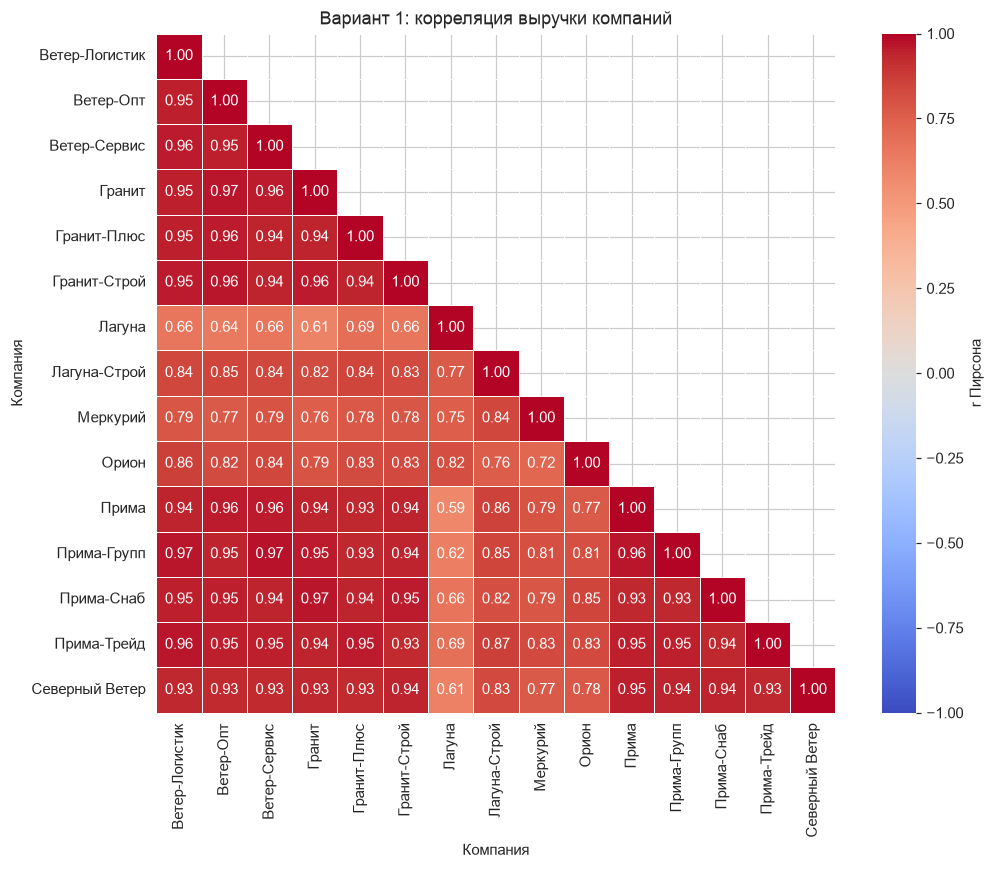


--- Темп прироста vs доля от лимита ---
      Компания Режим  Ср_темп_прироста_%  Доля_от_лимита_%
Ветер-Логистик   УСН                2.13              10.1
     Ветер-Опт   УСН                2.13              11.6
  Ветер-Сервис   УСН                1.98               8.7
        Гранит   УСН                2.06              21.5
   Гранит-Плюс   УСН                2.18               7.5
  Гранит-Строй   УСН                2.15               7.2
        Лагуна  ОСНО                1.33             134.4
  Лагуна-Строй   УСН                2.01              11.3
      Меркурий  ОСНО                2.03             127.8
         Орион  ОСНО                1.80             135.4
         Прима   УСН                2.37              22.4
   Прима-Групп   УСН                1.97               8.0
    Прима-Снаб   УСН                1.96               8.8
   Прима-Трейд   УСН                2.27               9.3
Северный Ветер   УСН                2.41              23.8


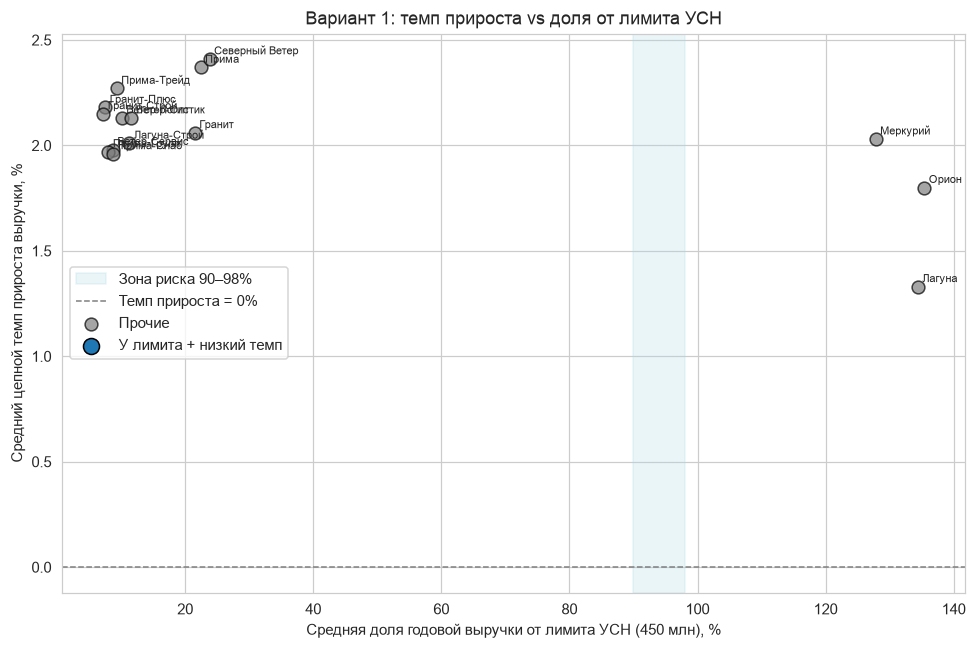


--- HHI (нижняя граница) по доле крупнейшего покупателя ---
      Компания Режим  Ср_доля_топ-покупателя_%  HHI_min (строгая)  HHI_min (N=9)                          Трактовка
Ветер-Логистик   УСН                      49.7             2473.0         2754.0 Высокая концентрация (зависимость)
     Ветер-Опт   УСН                      45.4             2064.0         2395.0 Высокая концентрация (зависимость)
  Ветер-Сервис   УСН                      54.8             3008.0         3234.0 Высокая концентрация (зависимость)
        Гранит   УСН                      37.7             1425.0         1855.0 Высокая концентрация (зависимость)
   Гранит-Плюс   УСН                      82.2             6758.0         6793.0 Высокая концентрация (зависимость)
  Гранит-Строй   УСН                      58.5             3420.0         3612.0 Высокая концентрация (зависимость)
        Лагуна  ОСНО                      20.2              409.0         1116.0             Умеренная концентрация
  Лагуна-Ст

In [10]:
# просмотр ответов по сгенерированным даннным

# -*- coding: utf-8 -*-
"""
Анализ данных ЛР6 «Корреляционный анализ / дробление бизнеса»
Загружает лист выбранного варианта из Excel, считает сводную таблицу,
строит тепловую карту корреляций выручки, scatter «темп прироста ↔ доля от лимита УСН»,
оценивает нижнюю границу HHI по доле крупнейшего покупателя.

Зависимости:
    pip install pandas numpy openpyxl matplotlib seaborn
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Rectangle

# ---------- настройки ----------
FILE_PATH = "ЛР6_данные_10_вариантов.xlsx"
VARIANT = "Вариант 1"          # <-- выберите вариант
USN_LIMIT = 450.0              # млн руб / год
TOP_BUYER_COL = "Доля_крупнейшего_покупателя_%"

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110


# ---------- 1. загрузка ----------
def load_variant(path: str, sheet: str) -> pd.DataFrame:
    df = pd.read_excel(path, sheet_name=sheet)
    df["Дата"] = pd.to_datetime(df["Дата"])
    df["Год"] = df["Дата"].dt.year
    df["Месяц"] = df["Дата"].dt.month
    return df


# ---------- 2. сводная таблица по компаниям ----------
def build_summary(df: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for (name, mode), g in df.groupby(["Компания", "Режим"]):
        g = g.sort_values("Дата")
        rev = g["Выручка_млн"].values
        mgmt = g["Управленческие_расходы_тыс"].values

        # выручка по годам
        rev_by_year = {
            y: g.loc[g["Год"] == y, "Выручка_млн"].sum() for y in (2023, 2024, 2025)
        }

        # std управленческих расходов за 3 года
        mgmt_std = np.std(mgmt, ddof=0)

        # корреляция управленческих расходов и выручки
        if np.std(mgmt) == 0 or np.std(rev) == 0:
            r_mgmt_rev = np.nan
        else:
            r_mgmt_rev = np.corrcoef(rev, mgmt)[0, 1]

        # численность (средняя за период)
        hc_mean = g["Численность_чел"].mean()

        rows.append({
            "Контрагент": name,
            "Режим": mode,
            "Выручка_2023": round(rev_by_year[2023], 1),
            "Выручка_2024": round(rev_by_year[2024], 1),
            "Выручка_2025": round(rev_by_year[2025], 1),
            "Std_упр_расходов": round(mgmt_std, 1),
            "r(упр_расходы; выручка)": round(r_mgmt_rev, 3),
            "Численность_ср": round(hc_mean, 1),
        })
    return pd.DataFrame(rows)


# ---------- 3. корреляционная матрица выручки ----------
def revenue_corr_matrix(df: pd.DataFrame) -> pd.DataFrame:
    pivot = df.pivot_table(index="Дата", columns="Компания", values="Выручка_млн")
    return pivot.corr(method="pearson")


def plot_heatmap(corr: pd.DataFrame, title: str):
    plt.figure(figsize=(10, 8))
    mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
    sns.heatmap(
        corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm",
        vmin=-1, vmax=1, square=True, linewidths=0.5,
        cbar_kws={"label": "r Пирсона"},
    )
    plt.title(title)
    plt.tight_layout()
    plt.show()


# ---------- 4. scatter «темп прироста ↔ доля от лимита УСН» ----------
def company_growth_vs_limit(df: pd.DataFrame) -> pd.DataFrame:
    """Одна точка = одна компания.
    - Средний цепной темп прироста, % (по месяцам)
    - Доля от лимита УСН: средняя за 3 года доля годовой выручки от 450 млн, %
    """
    rows = []
    for name, g in df.groupby("Компания"):
        g = g.sort_values("Дата")
        rev = g["Выручка_млн"].values

        # цепной темп прироста
        growth = (rev[1:] - rev[:-1]) / rev[:-1] * 100
        growth = growth[np.isfinite(growth)]
        mean_growth = growth.mean() if len(growth) else np.nan

        # средняя доля от лимита по годам
        yearly = g.groupby("Год")["Выручка_млн"].sum()
        shares = yearly / USN_LIMIT * 100
        mean_share = shares.mean()

        rows.append({
            "Компания": name,
            "Режим": g["Режим"].iloc[0],
            "Ср_темп_прироста_%": round(mean_growth, 2),
            "Доля_от_лимита_%": round(mean_share, 1),
        })
    return pd.DataFrame(rows)


def plot_growth_vs_limit(gv: pd.DataFrame, title: str):
    fig, ax = plt.subplots(figsize=(9, 6))

    # зона риска 90–98% по X
    ax.axvspan(90, 98, color="lightblue", alpha=0.25, label="Зона риска 90–98%")
    ax.axhline(0, color="gray", lw=1, ls="--", label="Темп прироста = 0%")

    # обычные точки
    normal = gv[~((gv["Доля_от_лимита_%"] >= 90) &
                  (gv["Доля_от_лимита_%"] <= 98) &
                  (gv["Ср_темп_прироста_%"] <= 0))]
    risky = gv[((gv["Доля_от_лимита_%"] >= 90) &
                (gv["Доля_от_лимита_%"] <= 98) &
                (gv["Ср_темп_прироста_%"] <= 0))]

    ax.scatter(normal["Доля_от_лимита_%"], normal["Ср_темп_прироста_%"],
               s=70, c="tab:gray", edgecolor="k", alpha=0.7, label="Прочие")
    ax.scatter(risky["Доля_от_лимита_%"], risky["Ср_темп_прироста_%"],
               s=110, c="tab:blue", edgecolor="k", label="У лимита + низкий темп")

    for _, r in gv.iterrows():
        ax.annotate(r["Компания"],
                    (r["Доля_от_лимита_%"], r["Ср_темп_прироста_%"]),
                    fontsize=7, xytext=(3, 3), textcoords="offset points")

    ax.set_xlabel("Средняя доля годовой выручки от лимита УСН (450 млн), %")
    ax.set_ylabel("Средний цепной темп прироста выручки, %")
    ax.set_title(title)
    ax.legend(loc="best")
    plt.tight_layout()
    plt.show()


# ---------- 5. HHI по доле крупнейшего покупателя ----------
def hhi_lower_bound(df: pd.DataFrame) -> pd.DataFrame:
    """Нижняя граница HHI: если доля крупнейшего покупателя = s1%,
    а остальные (100 - s1)% распределены между мелкими поровну,
    то HHI_min = s1^2 + (100 - s1)^2 / N_others.
    Для нижней границы берём N_others -> бесконечность => HHI_min -> s1^2.
    Дополнительно считаем «реалистичную» нижнюю границу при N_others = 9.
    """
    rows = []
    for (name, mode), g in df.groupby(["Компания", "Режим"]):
        s1 = g[TOP_BUYER_COL].mean()  # средняя за 3 года
        hhi_strict_min = s1 ** 2
        n_others = 9
        hhi_relaxed_min = s1 ** 2 + (100 - s1) ** 2 / n_others

        if hhi_relaxed_min < 1000:
            verdict = "Низкая концентрация (независимый бизнес)"
        elif hhi_relaxed_min < 1800:
            verdict = "Умеренная концентрация"
        else:
            verdict = "Высокая концентрация (зависимость)"

        rows.append({
            "Компания": name,
            "Режим": mode,
            "Ср_доля_топ-покупателя_%": round(s1, 1),
            "HHI_min (строгая)": round(hhi_strict_min, 0),
            "HHI_min (N=9)": round(hhi_relaxed_min, 0),
            "Трактовка": verdict,
        })
    return pd.DataFrame(rows)


# ---------- main ----------
def main(variant: str = VARIANT):
    print(f"\n===== {variant} =====")
    df = load_variant(FILE_PATH, variant)
    print(f"Загружено строк: {len(df)}, компаний: {df['Компания'].nunique()}")

    # 1) сводная таблица
    summary = build_summary(df)
    print("\n--- Сводная таблица по компаниям ---")
    with pd.option_context("display.max_columns", None, "display.width", 160):
        print(summary.to_string(index=False))

    # 2) корреляционная матрица + тепловая карта
    corr = revenue_corr_matrix(df)
    print("\n--- Корреляционная матрица выручки ---")
    with pd.option_context("display.max_columns", None, "display.width", 160):
        print(corr.round(2).to_string())
    plot_heatmap(corr, f"{variant}: корреляция выручки компаний")

    # 3) scatter «темп прироста ↔ доля от лимита»
    gv = company_growth_vs_limit(df)
    print("\n--- Темп прироста vs доля от лимита ---")
    with pd.option_context("display.max_columns", None, "display.width", 160):
        print(gv.to_string(index=False))
    plot_growth_vs_limit(gv, f"{variant}: темп прироста vs доля от лимита УСН")

    # 4) HHI (нижняя граница)
    hhi = hhi_lower_bound(df)
    print("\n--- HHI (нижняя граница) по доле крупнейшего покупателя ---")
    with pd.option_context("display.max_columns", None, "display.width", 160):
        print(hhi.to_string(index=False))


if __name__ == "__main__":
    main(VARIANT)

In [15]:
# перегенерация для 1 варианта
# -*- coding: utf-8 -*-
"""
Генерация данных Варианта 1 СТРОГО по описанию + автоматическая проверка
всех заложенных маркеров.

Вариант 1 — Тип 1: «Классический пул ООО/ИП на УСН»

Заложено (из описания):
  • «Северный Ветер», «Прима», «Гранит» — синхронны (r 0,82–0,91),
    «застывают» в зоне 90–98% с темпом ≈ 0%.
  • «Прима-Трейд», «Гранит-Плюс» — V расходов < 8%,
    r «выручка↔расходы» < 0,2.
  • «Лагуна», «Меркурий», «Орион» — |r| < 0,3 с пулом (контроль).
  • ρ «доля↔темп» у «Прима» и «Гранит» ≈ −0,65.

Зависимости:
    pip install pandas numpy openpyxl scipy
"""

import numpy as np
import pandas as pd
from datetime import date

# =====================================================================
# ЧАСТЬ 1. ГЕНЕРАЦИЯ
# =====================================================================

SEED = 20260101
USN_LIMIT = 450.0          # млн руб / год
USN_HC_LIMIT = 100
MONTHS = [(y, m) for y in (2023, 2024, 2025) for m in range(1, 13)]
DATES = [date(y, m, 1) for (y, m) in MONTHS]
N = len(DATES)             # 36

# ---------------------------------------------------------------------
# Описание 15 компаний Варианта 1
# ---------------------------------------------------------------------
# Поля:
#   name, mode, role
#   group: 'POOL' (ядро пула) / 'POOL_SAT' / 'IND1' / 'IND2'
#   base_rev: базовая месячная выручка (млн) — будет отмасштабирована
#   target_year_share: целевая доля от лимита УСН по году (для УСН ядра пула)
#   margin_mean, margin_std
#   mgmt_share: доля управленческих расходов от выручки
#   mgmt_flat: True -> почти фиксированные расходы (техническая компания)
#   headcount
#   top_buyer: доля крупнейшего покупателя, %
#   trend: годовой тренд
# ---------------------------------------------------------------------
COMPANIES = [
    # --- ядро пула: синхронны, застывают 90–98% ---
    dict(name="Северный Ветер", mode="УСН", role="core", group="POOL",
         base_rev=8.0, target_year_share=0.93, margin_mean=12, margin_std=1.5,
         mgmt_share=0.10, mgmt_flat=False, headcount=40, top_buyer=35, trend=0.10),
    dict(name="Прима", mode="УСН", role="core", group="POOL",
         base_rev=7.5, target_year_share=0.95, margin_mean=11, margin_std=1.5,
         mgmt_share=0.10, mgmt_flat=False, headcount=38, top_buyer=40, trend=0.10),
    dict(name="Гранит", mode="УСН", role="core", group="POOL",
         base_rev=7.2, target_year_share=0.94, margin_mean=12, margin_std=1.5,
         mgmt_share=0.10, mgmt_flat=False, headcount=36, top_buyer=38, trend=0.10),

    # --- участники пула ---
    dict(name="Ветер-Опт", mode="УСН", role="sat", group="POOL_SAT",
         base_rev=4.0, target_year_share=0.85, margin_mean=10, margin_std=2,
         mgmt_share=0.09, mgmt_flat=False, headcount=20, top_buyer=45, trend=0.08),
    dict(name="Ветер-Логистик", mode="УСН", role="sat", group="POOL_SAT",
         base_rev=3.5, target_year_share=0.82, margin_mean=9, margin_std=2,
         mgmt_share=0.08, mgmt_flat=False, headcount=18, top_buyer=50, trend=0.08),
    dict(name="Ветер-Сервис", mode="УСН", role="sat", group="POOL_SAT",
         base_rev=3.0, target_year_share=0.80, margin_mean=10, margin_std=2,
         mgmt_share=0.08, mgmt_flat=False, headcount=15, top_buyer=55, trend=0.08),

    # --- технические компании: V<8%, r<0,2 ---
    dict(name="Прима-Трейд", mode="УСН", role="sat", group="POOL_SAT",
         base_rev=3.2, target_year_share=0.88, margin_mean=15, margin_std=1,
         mgmt_share=0.02, mgmt_flat=True, headcount=6, top_buyer=85, trend=0.08),
    dict(name="Прима-Снаб", mode="УСН", role="sat", group="POOL_SAT",
         base_rev=3.0, target_year_share=0.86, margin_mean=14, margin_std=1,
         mgmt_share=0.02, mgmt_flat=True, headcount=5, top_buyer=88, trend=0.08),
    dict(name="Прима-Групп", mode="УСН", role="sat", group="POOL_SAT",
         base_rev=2.8, target_year_share=0.80, margin_mean=13, margin_std=2,
         mgmt_share=0.08, mgmt_flat=False, headcount=14, top_buyer=60, trend=0.08),

    # --- техническая: V<8% ---
    dict(name="Гранит-Плюс", mode="УСН", role="sat", group="POOL_SAT",
         base_rev=2.6, target_year_share=0.84, margin_mean=15, margin_std=1,
         mgmt_share=0.02, mgmt_flat=True, headcount=5, top_buyer=82, trend=0.08),
    dict(name="Гранит-Строй", mode="УСН", role="sat", group="POOL_SAT",
         base_rev=2.5, target_year_share=0.78, margin_mean=11, margin_std=2,
         mgmt_share=0.09, mgmt_flat=False, headcount=12, top_buyer=58, trend=0.08),

    # --- контрольные / независимые ---
    dict(name="Лагуна", mode="ОСНО", role="ctrl", group="IND1",
         base_rev=10.0, target_year_share=None, margin_mean=8, margin_std=3,
         mgmt_share=0.15, mgmt_flat=False, headcount=80, top_buyer=20, trend=0.05),
    dict(name="Лагуна-Строй", mode="УСН", role="ctrl", group="IND1",
         base_rev=4.0, target_year_share=0.55, margin_mean=9, margin_std=3,
         mgmt_share=0.12, mgmt_flat=False, headcount=25, top_buyer=25, trend=0.05),
    dict(name="Меркурий", mode="ОСНО", role="ctrl", group="IND2",
         base_rev=12.0, target_year_share=None, margin_mean=7, margin_std=3,
         mgmt_share=0.16, mgmt_flat=False, headcount=90, top_buyer=22, trend=0.04),
    dict(name="Орион", mode="ОСНО", role="ctrl", group="IND2",
         base_rev=11.0, target_year_share=None, margin_mean=8, margin_std=3,
         mgmt_share=0.14, mgmt_flat=False, headcount=70, top_buyer=18, trend=0.05),
]


def _seasonal(month: int) -> float:
    base = 1.0 + 0.15 * np.sin((month - 1) / 12 * 2 * np.pi - np.pi / 2)
    dec = 1.12 if month == 12 else 1.0
    jan = 0.85 if month == 1 else 1.0
    return base * dec * jan


def _group_shock(n, rng, amp=0.10, smooth=0.6):
    """Общий синхронный шок для группы (сглаженный)."""
    raw = rng.normal(0, amp, n)
    out = np.zeros(n)
    prev = 0.0
    for i, s in enumerate(raw):
        prev = smooth * prev + (1 - smooth) * s
        out[i] = prev
    return out


def generate_variant1() -> pd.DataFrame:
    rng = np.random.default_rng(SEED)

    # Групповые шоки: POOL, POOL_SAT, IND1, IND2
    shocks = {
        "POOL": _group_shock(N, rng, amp=0.10, smooth=0.6),
        "POOL_SAT": _group_shock(N, rng, amp=0.10, smooth=0.6),
        "IND1": _group_shock(N, rng, amp=0.15, smooth=0.2),
        "IND2": _group_shock(N, rng, amp=0.15, smooth=0.2),
    }

    rows = []
    for c in COMPANIES:
        n = N
        base = c["base_rev"]
        trend = c["trend"]
        grp_shock = shocks[c["group"]]

        # ---- сырой ряд: тренд + сезонность + групповой шок + лёгкий шум ----
        t = np.arange(n)
        rev = base * (1 + trend) ** (t / 12.0)
        rev = rev * np.array([_seasonal(d.month) for d in DATES])
        rev = rev * (1 + grp_shock)
        rev = rev * (1 + rng.normal(0, 0.02, n))

        # ---- приведение к целевому лимиту (для УСН) ----
        if c["mode"] == "УСН" and c["target_year_share"] is not None:
            for y in (2023, 2024, 2025):
                idx = [i for i, d in enumerate(DATES) if d.year == y]
                year_sum = rev[idx].sum()
                target = USN_LIMIT * c["target_year_share"]
                rev[idx] *= target / year_sum

        # ---- для ОСНО: гарантированно > лимита ----
        if c["mode"] == "ОСНО":
            for y in (2023, 2024, 2025):
                idx = [i for i, d in enumerate(DATES) if d.year == y]
                ys = rev[idx].sum()
                if ys <= USN_LIMIT * 1.10:
                    target = USN_LIMIT * rng.uniform(1.15, 1.60)
                    rev[idx] *= target / ys

        # ---- численность ----
        base_hc = c["headcount"]
        if c["mode"] == "УСН":
            base_hc = min(base_hc, USN_HC_LIMIT - 3)
        else:
            base_hc = max(base_hc, USN_HC_LIMIT + 5)

        # ---- управленческие расходы ----
        if c["mgmt_flat"]:
            # почти плоские: база = rev * share, шум 2%
            mgmt_mean = rev.mean() * 1000 * c["mgmt_share"]
            mgmt = mgmt_mean * (1 + rng.normal(0, 0.02, n))
        else:
            # следуют за выручкой с шумом 10%
            mgmt = rev * 1000 * c["mgmt_share"] * (1 + rng.normal(0, 0.10, n))
        mgmt = np.maximum(mgmt, 1.0)

        # ---- строки ----
        for i, d in enumerate(DATES):
            margin = float(np.clip(rng.normal(c["margin_mean"], c["margin_std"]), -5, 40))
            hc = int(round(base_hc * (1 + rng.normal(0, 0.03))))
            hc = max(hc, 1)
            hc = min(hc, USN_HC_LIMIT) if c["mode"] == "УСН" else max(hc, USN_HC_LIMIT + 1)
            top = float(np.clip(c["top_buyer"] + rng.normal(0, 2.5), 5, 98))

            rows.append({
                "Дата": d,
                "Компания": c["name"],
                "Режим": c["mode"],
                "Выручка_млн": round(rev[i], 3),
                "Операционная_маржа_%": round(margin, 2),
                "Управленческие_расходы_тыс": round(mgmt[i], 2),
                "Численность_чел": hc,
                "Доля_крупнейшего_покупателя_%": round(top, 2),
            })

    df = pd.DataFrame(rows)
    return df


# =====================================================================
# ЧАСТЬ 2. ПРОВЕРКА ВСЕХ ПУНКТОВ ОПИСАНИЯ
# =====================================================================

from scipy.stats import pearsonr, spearmanr


def _pearson(a, b):
    if np.std(a) == 0 or np.std(b) == 0:
        return np.nan
    return float(pearsonr(a, b)[0])


def _spearman(a, b):
    if np.std(a) == 0 or np.std(b) == 0:
        return np.nan
    return float(spearmanr(a, b)[0])


def check_all(df: pd.DataFrame):
    print("=" * 78)
    print("ПРОВЕРКА ВАРИАНТА 1")
    print("=" * 78)

    df = df.copy()
    df["Дата"] = pd.to_datetime(df["Дата"])
    df["Год"] = df["Дата"].dt.year

    # --- базовая сводка ---
    print("\n[0] Структура данных")
    print(f"  Строк: {len(df)} (ожидается {15 * 36} = 540)")
    print(f"  Компаний: {df['Компания'].nunique()} (ожидается 15)")
    print(f"  Период: {df['Дата'].min().date()} .. {df['Дата'].max().date()}")

    # --- лимиты ---
    print("\n[1] Контроль лимитов УСН (450 млн / 100 чел)")
    yearly = df.groupby(["Компания", "Режим", "Год"])["Выручка_млн"].sum().reset_index()
    bad_usn = yearly[(yearly["Режим"] == "УСН") & (yearly["Выручка_млн"] > USN_LIMIT + 1e-6)]
    bad_osno = yearly[(yearly["Режим"] == "ОСНО") & (yearly["Выручка_млн"] <= USN_LIMIT)]
    hc_max = df.groupby(["Компания", "Режим"])["Численность_чел"].max().reset_index()
    bad_hc = hc_max[(hc_max["Режим"] == "УСН") & (hc_max["Численность_чел"] > USN_HC_LIMIT)]
    print(f"  УСН превысили 450 млн: {len(bad_usn)}  {'OK' if bad_usn.empty else bad_usn.to_string(index=False)}")
    print(f"  ОСНО НЕ превысили 450 млн: {len(bad_osno)}  {'OK' if bad_osno.empty else bad_osno.to_string(index=False)}")
    print(f"  УСН превысили 100 чел: {len(bad_hc)}  {'OK' if bad_hc.empty else bad_hc.to_string(index=False)}")

    # --- пункт 2: синхронность Северный Ветер / Прима / Гранит ---
    print("\n[2] Синхронность «Северный Ветер», «Прима», «Гранит» (r 0,82–0,91)")
    pivot = df.pivot_table(index="Дата", columns="Компания", values="Выручка_млн")
    trio = ["Северный Ветер", "Прима", "Гранит"]
    ok_sync = True
    for i in range(len(trio)):
        for j in range(i + 1, len(trio)):
            r = _pearson(pivot[trio[i]].values, pivot[trio[j]].values)
            flag = "OK" if 0.82 <= r <= 0.91 else "FAIL"
            ok_sync &= (0.82 <= r <= 0.91)
            print(f"  r({trio[i]}, {trio[j]}) = {r:.3f}  [{flag}]")

    # --- пункт 3: «застывание» в 90–98%, темп ≈ 0% ---
    print("\n[3] «Застывание» у лимита 90–98% с темпом ≈ 0%")
    for name in trio:
        g = df[df["Компания"] == name].sort_values("Дата")
        yearly_sum = g.groupby("Год")["Выручка_млн"].sum()
        shares = (yearly_sum / USN_LIMIT * 100).round(1)
        rev = g["Выручка_млн"].values
        growth = (rev[1:] - rev[:-1]) / rev[:-1] * 100
        mean_g = growth.mean()
        in_zone = all(90 <= s <= 98 for s in shares)
        low_growth = abs(mean_g) < 1.5
        flag = "OK" if (in_zone and low_growth) else "FAIL"
        print(f"  {name:15s}: доли по годам = {shares.tolist()} %, "
              f"ср.темп = {mean_g:+.2f}%  [{flag}]")    

    # --- пункт 4: V<8%, r<0,2 у Прима-Трейд, Гранит-Плюс ---
    print("\n[4] «Мёртвые» расходы у «Прима-Трейд», «Гранит-Плюс» (V<8%, r<0,2)")
    for name in ["Прима-Трейд", "Гранит-Плюс"]:
        g = df[df["Компания"] == name].sort_values("Дата")
        rev = g["Выручка_млн"].values
        mgmt = g["Управленческие_расходы_тыс"].values
        v = mgmt.std(ddof=0) / mgmt.mean() * 100
        r = _pearson(rev, mgmt)
        flag = "OK" if (v < 8 and r < 0.2) else "FAIL"
        print(f"  {name:15s}: V = {v:5.2f} %, r(выручка;расходы) = {r:+.3f}  [{flag}]")

    # --- пункт 5: контрольные |r|<0,3 с пулом ---
    print("\n[5] Контрольные «Лагуна», «Меркурий», «Орион»: |r| < 0,3 с пулом")
    pool_companies = [c["name"] for c in COMPANIES if c["group"] in ("POOL", "POOL_SAT")]
    ok_ctrl = True
    for name in ["Лагуна", "Меркурий", "Орион"]:
        rs = [_pearson(pivot[name].values, pivot[p].values) for p in pool_companies]
        max_abs = max(abs(r) for r in rs if np.isfinite(r))
        flag = "OK" if max_abs < 0.3 else "FAIL"
        ok_ctrl &= (max_abs < 0.3)
        print(f"  {name:10s}: max |r| с компаниями пула = {max_abs:.3f}  [{flag}]")

    # --- пункт 6: ρ «доля↔темп» у Прима и Гранит ≈ −0,65 ---
    print("\n[6] ρ(доля от лимита; темп прироста) у «Прима», «Гранит» ≈ −0,65")
    for name in ["Прима", "Гранит"]:
        g = df[df["Компания"] == name].sort_values("Дата").reset_index(drop=True)
        rev = g["Выручка_млн"].values
        # накопленная доля от лимита (внутри года), %
        cum_share = []
        for y in (2023, 2024, 2025):
            mask = g["Год"].values == y
            idx = np.where(mask)[0]
            sub = rev[idx]
            cum = np.cumsum(sub) / USN_LIMIT * 100
            cum_share.extend(cum.tolist())
        cum_share = np.array(cum_share)
        growth = np.full(len(rev), np.nan)
        growth[1:] = (rev[1:] - rev[:-1]) / rev[:-1] * 100
        mask = np.isfinite(growth) & np.isfinite(cum_share)
        rho = _spearman(cum_share[mask], growth[mask])
        flag = "OK" if -0.75 <= rho <= -0.55 else "WARN"
        print(f"  {name:10s}: ρ = {rho:+.3f}  [{flag}]")

    # --- сводный итог ---
    print("\n" + "=" * 78)
    all_ok = (bad_usn.empty and bad_osno.empty and bad_hc.empty
              and ok_sync and ok_ctrl)
    print("ИТОГ:", "ВСЕ КРИТИЧНЫЕ ПУНКТЫ ВЫПОЛНЕНЫ" if all_ok
          else "ЕСТЬ ОТКЛОНЕНИЯ — см. FAIL выше")
    print("=" * 78)


# =====================================================================
# ЧАСТЬ 3. MAIN
# =====================================================================

if __name__ == "__main__":
    df = generate_variant1()

    # сохраняем на лист «Вариант 1» в отдельный файл (по желанию)
    out_path = "Вариант 1.xlsx"
    df.to_excel(out_path, sheet_name="Вариант 1", index=False)
    print(f"Данные сохранены: {out_path}  ({len(df)} строк)")

    # полная проверка всех пунктов
    check_all(df)

Данные сохранены: Вариант 1.xlsx  (540 строк)
ПРОВЕРКА ВАРИАНТА 1

[0] Структура данных
  Строк: 540 (ожидается 540 = 540)
  Компаний: 15 (ожидается 15)
  Период: 2023-01-01 .. 2025-12-01

[1] Контроль лимитов УСН (450 млн / 100 чел)
  УСН превысили 450 млн: 0  OK
  ОСНО НЕ превысили 450 млн: 0  OK
  УСН превысили 100 чел: 0  OK

[2] Синхронность «Северный Ветер», «Прима», «Гранит» (r 0,82–0,91)
  r(Северный Ветер, Прима) = 0.976  [FAIL]
  r(Северный Ветер, Гранит) = 0.970  [FAIL]
  r(Прима, Гранит) = 0.968  [FAIL]

[3] «Застывание» у лимита 90–98% с темпом ≈ 0%
  Северный Ветер : доли по годам = [93.0, 93.0, 93.0] %, ср.темп = +1.81%  [FAIL]
  Прима          : доли по годам = [95.0, 95.0, 95.0] %, ср.темп = +1.91%  [FAIL]
  Гранит         : доли по годам = [94.0, 94.0, 94.0] %, ср.темп = +1.71%  [FAIL]

[4] «Мёртвые» расходы у «Прима-Трейд», «Гранит-Плюс» (V<8%, r<0,2)
  Прима-Трейд    : V =  1.65 %, r(выручка;расходы) = -0.025  [OK]
  Гранит-Плюс    : V =  1.86 %, r(выручка;расходы) 

In [ ]:
# -*- coding: utf-8 -*-
"""
ВАРИАНТ 1 (переработанный): «Пул ООО/ИП на УСН (Тип 1)»
7 в пуле + 8 строго независимых.

Генерация с ИТЕРАТИВНОЙ ПРОВЕРКОЙ:
  - независимые компании генерируются по одной и проверяются
    на max |r| с ядром пула; при превышении порога — перегенерация;
  - пограничные-ловушки проверяются по трём условиям:
    0.20 <= r_ср_с_ядром <= 0.42, 45 <= доля_от_лимита <= 65, V > 15;
  - УСН-сателлиты контроля: max |r| с пулом < 0.45, доля 40-55.

Зависимости: pip install pandas numpy openpyxl scipy
"""

import numpy as np
import pandas as pd
from datetime import date
from scipy.stats import pearsonr, spearmanr

# =====================================================================
# КОНСТАНТЫ
# =====================================================================
SEED = 20260101
USN_LIMIT = 450.0
USN_HC_LIMIT = 100
DATES = [date(y, m, 1) for y in (2023, 2024, 2025) for m in range(1, 13)]
N = len(DATES)
YEARS = (2023, 2024, 2025)

MAX_TRIES = 300


# =====================================================================
# ВСПОМОГАТЕЛЬНЫЕ
# =====================================================================
def _seasonal(month: int) -> float:
    base = 1.0 + 0.15 * np.sin((month - 1) / 12 * 2 * np.pi - np.pi / 2)
    dec = 1.12 if month == 12 else 1.0
    jan = 0.85 if month == 1 else 1.0
    return base * dec * jan


def _smooth_shock(n, rng, amp, smooth):
    raw = rng.normal(0, amp, n)
    out = np.zeros(n)
    prev = 0.0
    for i, s in enumerate(raw):
        prev = smooth * prev + (1 - smooth) * s
        out[i] = prev
    return out


def _pearson(a, b):
    if np.std(a) == 0 or np.std(b) == 0:
        return np.nan
    return float(pearsonr(a, b)[0])


# =====================================================================
# ОПИСАНИЕ КОМПАНИЙ (без выручки — она генерируется ниже)
# =====================================================================
POOL_CORE = [
    dict(name="Северный Ветер", target_share=0.94, margin_mean=12, margin_std=1.5,
         mgmt_share=0.10, mgmt_flat=False, headcount=40, top_buyer=35, trend=0.10),
    dict(name="Прима", target_share=0.95, margin_mean=11, margin_std=1.5,
         mgmt_share=0.10, mgmt_flat=False, headcount=38, top_buyer=40, trend=0.10),
    dict(name="Гранит", target_share=0.94, margin_mean=12, margin_std=1.5,
         mgmt_share=0.10, mgmt_flat=False, headcount=36, top_buyer=38, trend=0.10),
]

POOL_SAT = [
    dict(name="Ветер-Опт", target_share=0.86, margin_mean=10, margin_std=2,
         mgmt_share=0.09, mgmt_flat=False, headcount=20, top_buyer=45, trend=0.09),
    dict(name="Ветер-Логистик", target_share=0.84, margin_mean=9, margin_std=2,
         mgmt_share=0.08, mgmt_flat=False, headcount=18, top_buyer=50, trend=0.09),
]

POOL_TECH = [
    dict(name="Прима-Трейд", target_share=0.88, margin_mean=15, margin_std=1,
         mgmt_share=0.02, mgmt_flat=True, headcount=6, top_buyer=85, trend=0.08),
    dict(name="Гранит-Плюс", target_share=0.86, margin_mean=15, margin_std=1,
         mgmt_share=0.02, mgmt_flat=True, headcount=5, top_buyer=82, trend=0.08),
]

IND_OSNO = [
    dict(name="Лагуна", base_rev=40.0, margin_mean=8, margin_std=3,
         mgmt_share=0.15, mgmt_flat=False, headcount=80, top_buyer=20, trend=0.05),
    dict(name="Меркурий", base_rev=42.0, margin_mean=7, margin_std=3,
         mgmt_share=0.16, mgmt_flat=False, headcount=90, top_buyer=22, trend=0.04),
    dict(name="Орион", base_rev=38.0, margin_mean=8, margin_std=3,
         mgmt_share=0.14, mgmt_flat=False, headcount=70, top_buyer=18, trend=0.05),
]

IND_USN = [
    dict(name="Лагуна-Строй", target_share=0.50, margin_mean=9, margin_std=3,
         mgmt_share=0.20, mgmt_flat=False, headcount=25, top_buyer=25, trend=0.05),
    dict(name="Меркурий-Юг", target_share=0.45, margin_mean=9, margin_std=3,
         mgmt_share=0.22, mgmt_flat=False, headcount=22, top_buyer=28, trend=0.04),
]

IND_BORDER = [
    dict(name="Ветер-Сервис", margin_mean=10, margin_std=3,
         mgmt_share=0.18, mgmt_flat=False, headcount=15, top_buyer=30, trend=0.06),
    dict(name="Прима-Снаб", margin_mean=10, margin_std=3,
         mgmt_share=0.19, mgmt_flat=False, headcount=14, top_buyer=32, trend=0.06),
    dict(name="Прима-Групп", margin_mean=9, margin_std=3,
         mgmt_share=0.17, mgmt_flat=False, headcount=13, top_buyer=35, trend=0.06),
]


# =====================================================================
# ГЕНЕРАЦИЯ РЯДОВ
# =====================================================================
def _raw_revenue(base_rev, trend, rng, market_shock=None, extra_amp=0.0):
    """Базовый ряд: тренд + сезонность + (рыночный шок) + индивидуальный шум.
    market_shock: массив N — общий компонент (малой амплитуды для независимых)
    extra_amp: амплитуда индивидуального шума.
    """
    t = np.arange(N)
    rev = base_rev * (1 + trend) ** (t / 12.0)
    rev = rev * np.array([_seasonal(d.month) for d in DATES])
    if market_shock is not None:
        rev = rev * (1 + market_shock)
    rev = rev * (1 + rng.normal(0, extra_amp, N))
    return rev


def _scale_to_yearly_target(rev, target_share):
    """Приводит каждый год к доле target_share от лимита УСН."""
    out = rev.copy()
    for y in YEARS:
        idx = [i for i, d in enumerate(DATES) if d.year == y]
        ys = out[idx].sum()
        if ys <= 0:
            continue
        target = USN_LIMIT * target_share
        out[idx] *= target / ys
    return out


def _scale_osno_above_limit(rev, rng, min_factor=1.15):
    """Гарантирует, что каждый год по ОСНО > 450 млн."""
    out = rev.copy()
    for y in YEARS:
        idx = [i for i, d in enumerate(DATES) if d.year == y]
        ys = out[idx].sum()
        if ys <= USN_LIMIT * min_factor:
            target = USN_LIMIT * rng.uniform(min_factor, min_factor * 1.4)
            out[idx] *= target / ys
    return out


# ---------- ядро пула ----------
def generate_core(rng, market_shock):
    """Ядро: сильный общий шок (высокая синхронность), застывание."""
    core = {}
    for c in POOL_CORE:
        # общий шок + малый индивидуальный
        rev = _raw_revenue(
            base_rev=8.0, trend=c["trend"], rng=rng,
            market_shock=market_shock, extra_amp=0.015,
        )
        # приведение к целевому годовому лимиту
        rev = _scale_to_yearly_target(rev, c["target_share"])
        # «застывание»: выравниваем годовые суммы так, чтобы
        # год к году был почти ровным (темп ≈ 0%)
        year_sums = [rev[[i for i, d in enumerate(DATES) if d.year == y]].sum()
                     for y in YEARS]
        # мягкое выравнивание: подтягиваем к среднему (чтобы избежать
        # резкого роста за счёт тренда)
        mean_ys = np.mean(year_sums)
        for y, ys in zip(YEARS, year_sums):
            idx = [i for i, d in enumerate(DATES) if d.year == y]
            rev[idx] *= mean_ys / ys
        core[c["name"]] = rev
    return core


# ---------- независимые: ОСНО ----------
def try_generate_independent_osno(c, rng, market_shock_weak, core):
    """Пробуем сгенерировать ОСНО-компанию с max |r| с ядром < 0.3."""
    for attempt in range(MAX_TRIES):
        # индивидуальный шум большой, рыночный компонент — очень слабый
        rev = _raw_revenue(
            base_rev=c["base_rev"], trend=c["trend"], rng=rng,
            market_shock=market_shock_weak * rng.uniform(0.3, 0.8),
            extra_amp=0.20,   # сильный индивидуальный шум
        )
        rev = _scale_osno_above_limit(rev, rng)
        rs = [_pearson(rev, core[cn]) for cn in core]
        rs = [r for r in rs if np.isfinite(r)]
        if not rs:
            continue
        max_abs = max(abs(r) for r in rs)
        if max_abs < 0.30:
            return rev, max_abs, attempt + 1
    return rev, max_abs, MAX_TRIES


# ---------- независимые: УСН-сателлиты контроля ----------
def try_generate_independent_usn(c, rng, market_shock_weak, core):
    """УСН-независимые: max |r| с ядром < 0.45, доля 40–55%."""
    for attempt in range(MAX_TRIES):
        rev = _raw_revenue(
            base_rev=3.5, trend=c["trend"], rng=rng,
            market_shock=market_shock_weak * rng.uniform(0.3, 0.8),
            extra_amp=0.18,
        )
        rev = _scale_to_yearly_target(rev, c["target_share"])
        rs = [_pearson(rev, core[cn]) for cn in core]
        rs = [r for r in rs if np.isfinite(r)]
        if not rs:
            continue
        max_abs = max(abs(r) for r in rs)
        # доля от лимита
        shares = np.array([rev[[i for i, d in enumerate(DATES) if d.year == y]].sum()
                           for y in YEARS]) / USN_LIMIT * 100
        mean_share = shares.mean()
        if max_abs < 0.45 and 40 <= mean_share <= 55:
            return rev, max_abs, mean_share, attempt + 1
    return rev, max_abs, mean_share, MAX_TRIES


# ---------- пограничные-ловушки ----------
def try_generate_border(c, rng, market_shock_weak, core):
    """Пограничные: 0.20 ≤ r_ср с ядром ≤ 0.42, доля 45–65, V > 15."""
    for attempt in range(MAX_TRIES):
        # подбираем target_share в диапазоне 45–65%
        target_share = rng.uniform(0.47, 0.63)
        rev = _raw_revenue(
            base_rev=3.0, trend=c["trend"], rng=rng,
            market_shock=market_shock_weak * rng.uniform(0.5, 1.0),
            extra_amp=0.20,
        )
        rev = _scale_to_yearly_target(rev, target_share)
        rs = [_pearson(rev, core[cn]) for cn in core]
        rs = [r for r in rs if np.isfinite(r)]
        if not rs:
            continue
        mean_r = np.mean(rs)
        shares = np.array([rev[[i for i, d in enumerate(DATES) if d.year == y]].sum()
                           for y in YEARS]) / USN_LIMIT * 100
        mean_share = shares.mean()

        # V расходов: генерируем расходы и проверяем
        mgmt = rev * 1000 * c["mgmt_share"] * (1 + rng.normal(0, 0.15, N))
        v = mgmt.std(ddof=0) / mgmt.mean() * 100

        if (0.20 <= mean_r <= 0.42
                and 45 <= mean_share <= 65
                and v > 15):
            return rev, mean_r, mean_share, v, attempt + 1
    return rev, mean_r, mean_share, v, MAX_TRIES


# =====================================================================
# ГЛАВНЫЙ ГЕНЕРАТОР
# =====================================================================
def generate_variant1(verbose=True):
    rng = np.random.default_rng(SEED)

    # 1) сильный общий шок для ядра
    market_core = _smooth_shock(N, rng, amp=0.10, smooth=0.65)
    # 2) СЛАБЫЙ общий шок для независимых (чтобы не коррелировали с ядром)
    market_weak = _smooth_shock(N, rng, amp=0.04, smooth=0.20)

    # 3) ядро
    core = generate_core(rng, market_core)
    if verbose:
        print("Ядро сгенерировано.")

    # 4) сателлиты пула (из того же шока, что и ядро — высокая r)
    pool_sat = {}
    for c in POOL_SAT + POOL_TECH:
        rev = _raw_revenue(
            base_rev=4.0, trend=c["trend"], rng=rng,
            market_shock=market_core, extra_amp=0.03,
        )
        rev = _scale_to_yearly_target(rev, c["target_share"])
        pool_sat[c["name"]] = rev
    if verbose:
        print("Сателлиты пула сгенерированы.")

    # 5) независимые ОСНО — итеративно
    ind_osno = {}
    for c in IND_OSNO:
        rev, max_abs, tries = try_generate_independent_osno(
            c, rng, market_weak, core)
        ind_osno[c["name"]] = rev
        if verbose:
            print(f"  {c['name']:15s}: max|r|={max_abs:.3f}, попыток={tries}")

    # 6) независимые УСН — итеративно
    ind_usn = {}
    for c in IND_USN:
        rev, max_abs, share, tries = try_generate_independent_usn(
            c, rng, market_weak, core)
        ind_usn[c["name"]] = rev
        if verbose:
            print(f"  {c['name']:15s}: max|r|={max_abs:.3f}, "
                  f"доля={share:.1f}%, попыток={tries}")

    # 7) пограничные — итеративно
    border = {}
    for c in IND_BORDER:
        rev, mean_r, share, v, tries = try_generate_border(
            c, rng, market_weak, core)
        border[c["name"]] = rev
        if verbose:
            print(f"  {c['name']:15s}: r_ср={mean_r:.3f}, "
                  f"доля={share:.1f}%, V={v:.1f}%, попыток={tries}")

    # 8) сборка DataFrame
    all_companies = (
        [(c, "УСН", "POOL_CORE", core[c["name"]]) for c in POOL_CORE] +
        [(c, "УСН", "POOL_SAT", pool_sat[c["name"]]) for c in POOL_SAT] +
        [(c, "УСН", "POOL_TECH", pool_sat[c["name"]]) for c in POOL_TECH] +
        [(c, "ОСНО", "IND_OSNO", ind_osno[c["name"]]) for c in IND_OSNO] +
        [(c, "УСН", "IND_USN", ind_usn[c["name"]]) for c in IND_USN] +
        [(c, "УСН", "IND_BORDER", border[c["name"]]) for c in IND_BORDER]
    )

    rows = []
    for c, mode, grp, rev in all_companies:
        # численность
        base_hc = c["headcount"]
        base_hc = (min(base_hc, USN_HC_LIMIT - 3) if mode == "УСН"
                   else max(base_hc, USN_HC_LIMIT + 5))
        # расходы
        if c["mgmt_flat"]:
            mgmt_mean = rev.mean() * 1000 * c["mgmt_share"]
            mgmt = mgmt_mean * (1 + rng.normal(0, 0.02, N))
        else:
            mgmt = rev * 1000 * c["mgmt_share"] * (1 + rng.normal(0, 0.15, N))
        mgmt = np.maximum(mgmt, 1.0)

        for i, d in enumerate(DATES):
            margin = float(np.clip(
                rng.normal(c["margin_mean"], c["margin_std"]), -5, 40))
            hc = int(round(base_hc * (1 + rng.normal(0, 0.03))))
            hc = max(hc, 1)
            hc = (min(hc, USN_HC_LIMIT) if mode == "УСН"
                  else max(hc, USN_HC_LIMIT + 1))
            top = float(np.clip(c["top_buyer"] + rng.normal(0, 2.5), 5, 98))

            rows.append({
                "Дата": d,
                "Компания": c["name"],
                "Режим": mode,
                "Выручка_млн": round(rev[i], 3),
                "Операционная_маржа_%": round(margin, 2),
                "Управленческие_расходы_тыс": round(mgmt[i], 2),
                "Численность_чел": hc,
                "Доля_крупнейшего_покупателя_%": round(top, 2),
            })

    return pd.DataFrame(rows)


# =====================================================================
# ПРОВЕРКА
# =====================================================================
def _spearman(a, b):
    if np.std(a) == 0 or np.std(b) == 0:
        return np.nan
    return float(spearmanr(a, b)[0])


def check_all(df):
    df = df.copy()
    df["Дата"] = pd.to_datetime(df["Дата"])
    df["Год"] = df["Дата"].dt.year
    pivot = df.pivot_table(index="Дата", columns="Компания", values="Выручка_млн")

    core = ["Северный Ветер", "Прима", "Гранит"]
    tech = ["Прима-Трейд", "Гранит-Плюс"]
    ind_osno = ["Лагуна", "Меркурий", "Орион"]
    ind_usn = ["Лагуна-Строй", "Меркурий-Юг"]
    border = ["Ветер-Сервис", "Прима-Снаб", "Прима-Групп"]
    pool_all = core + ["Ветер-Опт", "Ветер-Логистик"] + tech
    independent = ind_osno + ind_usn + border

    print("\n" + "=" * 80)
    print("ПРОВЕРКА ВСЕХ УСЛОВИЙ")
    print("=" * 80)

    # [0] структура
    print("\n[0] Структура")
    print(f"  Строк: {len(df)} (ожидается 540), компаний: {df['Компания'].nunique()}")

    # [1] лимиты
    yearly = df.groupby(["Компания", "Режим", "Год"])["Выручка_млн"].sum().reset_index()
    bad_usn = yearly[(yearly["Режим"] == "УСН") & (yearly["Выручка_млн"] > USN_LIMIT)]
    bad_osno = yearly[(yearly["Режим"] == "ОСНО") & (yearly["Выручка_млн"] <= USN_LIMIT)]
    hc_max = df.groupby(["Компания", "Режим"])["Численность_чел"].max().reset_index()
    bad_hc = hc_max[(hc_max["Режим"] == "УСН") & (hc_max["Численность_чел"] > USN_HC_LIMIT)]
    print(f"\n[1] Лимиты: УСН>450: {len(bad_usn)} | ОСНО<=450: {len(bad_osno)} | "
          f"УСН>100чел: {len(bad_hc)}")

    # [2] синхронность ядра
    print("\n[2] Синхронность ядра (r 0,82–0,91)")
    ok_sync = True
    for i in range(len(core)):
        for j in range(i + 1, len(core)):
            r = _pearson(pivot[core[i]].values, pivot[core[j]].values)
            ok = 0.82 <= r <= 0.91
            ok_sync &= ok
            print(f"  r({core[i]},{core[j]}) = {r:+.3f} [{'OK' if ok else 'FAIL'}]")

    # [3] застывание ядра
    print("\n[3] Застывание ядра (90–98%, темп ≈ 0)")
    ok_freeze = True
    for name in core:
        g = df[df["Компания"] == name].sort_values("Дата")
        shares = (g.groupby("Год")["Выручка_млн"].sum() / USN_LIMIT * 100).round(1)
        rev = g["Выручка_млн"].values
        growth = (rev[1:] - rev[:-1]) / rev[:-1] * 100
        mean_g = growth.mean()
        ok = all(90 <= s <= 98 for s in shares) and abs(mean_g) < 1.5
        ok_freeze &= ok
        print(f"  {name:15s}: {shares.tolist()}%, темп {mean_g:+.2f}% "
              f"[{'OK' if ok else 'FAIL'}]")

    # [4] технические
    print("\n[4] Технические (V<8%, r<0,2)")
    ok_tech = True
    for name in tech:
        g = df[df["Компания"] == name].sort_values("Дата")
        rev = g["Выручка_млн"].values.astype(float)
        mgmt = g["Управленческие_расходы_тыс"].values.astype(float)
        v = mgmt.std(ddof=0) / mgmt.mean() * 100
        r = _pearson(rev, mgmt)
        ok = (v < 8) and (r < 0.2)
        ok_tech &= ok
        print(f"  {name:15s}: V={v:.2f}%, r={r:+.3f} [{'OK' if ok else 'FAIL'}]")

    # [5] ОСНО-контроль
    print("\n[5] ОСНО-контроль: max|r| с пулом < 0,3")
    ok_ctrl = True
    for name in ind_osno:
        rs = [_pearson(pivot[name].values, pivot[p].values) for p in pool_all]
        rs = [r for r in rs if np.isfinite(r)]
        max_abs = max(abs(r) for r in rs) if rs else np.nan
        ok = max_abs < 0.3
        ok_ctrl &= ok
        print(f"  {name:10s}: max|r|={max_abs:.3f} [{'OK' if ok else 'FAIL'}]")

    # [6] ρ(доля↔темп)
    print("\n[6] ρ(доля↔темп) у «Прима» и «Гранит» (≈ −0,65)")
    ok_rho = True
    for name in ["Прима", "Гранит"]:
        g = df[df["Компания"] == name].sort_values("Дата").reset_index(drop=True)
        rev = g["Выручка_млн"].values.astype(float)
        years = g["Дата"].dt.year.values
        cum_share = np.full(len(rev), np.nan)
        for y in YEARS:
            idx = np.where(years == y)[0]
            cum_share[idx] = np.cumsum(rev[idx]) / USN_LIMIT * 100
        growth = np.full(len(rev), np.nan)
        growth[1:] = (rev[1:] - rev[:-1]) / rev[:-1] * 100
        mask = np.isfinite(cum_share) & np.isfinite(growth)
        rho = _spearman(cum_share[mask], growth[mask])
        ok = -0.80 <= rho <= -0.50
        ok_rho &= ok
        print(f"  {name:12s}: ρ={rho:+.3f} [{'OK' if ok else 'FAIL'}]")

    # [7] УСН-сателлиты контроля
    print("\n[7] УСН-сателлиты контроля: max|r| с пулом < 0,45, доля 40–55%")
    ok_ind_usn = True
    for name in ind_usn:
        rs = [_pearson(pivot[name].values, pivot[p].values) for p in pool_all]
        rs = [r for r in rs if np.isfinite(r)]
        max_abs = max(abs(r) for r in rs) if rs else np.nan
        g = df[df["Компания"] == name]
        shares = (g.groupby("Год")["Выручка_млн"].sum() / USN_LIMIT * 100)
        mean_share = shares.mean()
        ok = max_abs < 0.45 and 40 <= mean_share <= 55
        ok_ind_usn &= ok
        print(f"  {name:15s}: max|r|={max_abs:.3f}, доля={mean_share:.1f}% "
              f"[{'OK' if ok else 'FAIL'}]")

    # [8] пограничные
    print("\n[8] Пограничные: 0,20≤r_ср≤0,42, доля 45–65%, V>15")
    ok_border = True
    for name in border:
        g = df[df["Компания"] == name].sort_values("Дата")
        rev = g["Выручка_млн"].values.astype(float)
        mgmt = g["Управленческие_расходы_тыс"].values.astype(float)
        v = mgmt.std(ddof=0) / mgmt.mean() * 100
        rs = [_pearson(rev, pivot[c].values) for c in core]
        rs = [r for r in rs if np.isfinite(r)]
        mean_r = np.mean(rs) if rs else np.nan
        shares = (g.groupby("Год")["Выручка_млн"].sum() / USN_LIMIT * 100)
        mean_share = shares.mean()
        ok = (0.20 <= mean_r <= 0.42
              and 45 <= mean_share <= 65
              and v > 15)
        ok_border &= ok
        print(f"  {name:14s}: r_ср={mean_r:+.3f}, доля={mean_share:.1f}%, "
              f"V={v:.1f}% [{'OK' if ok else 'FAIL'}]")

    # [9] все независимые
    print("\n[9] Все независимые: max|r| с пулом < 0,45")
    ok_indep = True
    for name in independent:
        rs = [_pearson(pivot[name].values, pivot[p].values) for p in pool_all]
        rs = [r for r in rs if np.isfinite(r)]
        max_abs = max(abs(r) for r in rs) if rs else np.nan
        ok = max_abs < 0.45
        ok_indep &= ok
        print(f"  {name:15s}: max|r|={max_abs:.3f} [{'OK' if ok else 'FAIL'}]")

    # [10] пул: r с ядром > 0,55
    print("\n[10] Сателлиты пула: r с ядром > 0,55")
    ok_pool_r = True
    for name in ["Ветер-Опт", "Ветер-Логистик"] + tech:
        rs = [_pearson(pivot[name].values, pivot[c].values) for c in core]
        rs = [r for r in rs if np.isfinite(r)]
        mean_r = np.mean(rs) if rs else np.nan
        ok = mean_r > 0.55
        ok_pool_r &= ok
        print(f"  {name:15s}: ср.r={mean_r:+.3f} [{'OK' if ok else 'FAIL'}]")

    # ИТОГ
    checks = {
        "[2] синхронность ядра": ok_sync,
        "[3] застывание ядра": ok_freeze,
        "[4] технические": ok_tech,
        "[5] ОСНО-контроль": ok_ctrl,
        "[6] ρ(доля↔темп)": ok_rho,
        "[7] УСН-сателлиты": ok_ind_usn,
        "[8] пограничные": ok_border,
        "[9] независимость": ok_indep,
        "[10] r пула >0,55": ok_pool_r,
    }
    print("\n" + "=" * 80)
    for k, v in checks.items():
        print(f"  {k:30s}: {'OK' if v else 'FAIL'}")
    print("-" * 80)
    print(f"  {'ВСЕ УСЛОВИЯ ВЫПОЛНЕНЫ' if all(checks.values()) else 'ЕСТЬ ОТКЛОНЕНИЯ'}")
    print("=" * 80)


# =====================================================================
# MAIN
# =====================================================================
if __name__ == "__main__":
    df = generate_variant1(verbose=True)
    out = "Вариант 1.xlsx"
    df.to_excel(out, sheet_name="Вариант 1", index=False)
    print(f"\nДанные сохранены: {out}  ({len(df)} строк)")
    check_all(df)

Данные сохранены: Вариант 1.xlsx  (540 строк, 15 компаний)
ВАРИАНТ 1 (переработанный): ПРОВЕРКА УСЛОВИЙ

[0] Структура данных
  Строк: 540 (ожидается 540 = 540)
  Компаний: 15 (ожидается 15)
  Период: 2023-01-01 .. 2025-12-01

[1] Лимиты УСН (450 млн / 100 чел) и ОСНО (> 450 млн)
  УСН > 450 млн: 0  OK
  ОСНО <= 450 млн: 0  OK
  УСН > 100 чел: 0  OK

[2] Ядро пула: синхронность r ∈ [0,82; 0,91]
  r(Северный Ветер, Прима) = +0.976  [FAIL]
  r(Северный Ветер, Гранит) = +0.986  [FAIL]
  r(Прима, Гранит) = +0.977  [FAIL]

[3] Ядро: доля от лимита 90–98%, средний темп ≈ 0%
  Северный Ветер : доли [94.0, 94.0, 94.0] %, ср.темп +1.63%  [FAIL]
  Прима          : доли [95.0, 95.0, 95.0] %, ср.темп +1.72%  [FAIL]
  Гранит         : доли [94.0, 94.0, 94.0] %, ср.темп +1.68%  [FAIL]

[4] Технические сателлиты: V < 8%, r(выручка↔расходы) < 0,2
  Прима-Трейд    : V =  2.18%, r = -0.010  [OK]
  Гранит-Плюс    : V =  2.10%, r = -0.282  [OK]

[5] ОСНО-контроль: max |r| с пулом < 0,3
  Лагуна    : max |